# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и искусственный интеллект

**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)

**Датасет:** *Telco Customer Churn* (IBM / Kaggle)

**Выполнил:** Боттер Вадим Валерьевич

**Группа:** ПКТб-23-1

**Преподаватель:** *Спирин Игорь Сергеевич*

**Ссылка на репозиторий:** https://github.com/uat0/ml-course-botter

**Путь к модулю:** `module-3-churn/notebook.ipynb`

**Дата сдачи:** 2026-10-26

## Введение

**1. Какую задачу решаем.** Телеком-оператор хочет заранее знать, какие абоненты собираются уйти к конкуренту. По 19 характеристикам клиента (демография, подключённые услуги, тип контракта, способ оплаты, суммы платежей) нужно предсказать бинарную метку `Churn`: **1 — клиент ушёл в последний месяц, 0 — остался**. Это задача **бинарной классификации с умеренным дисбалансом классов** (≈ 73.5% / 26.5%).

**2. Что такое ансамблевые методы.** Ансамбль — это модель, которая объединяет ответы многих базовых моделей (обычно деревьев решений) в один прогноз. Каждое отдельное дерево ошибается, но ошибается *по-разному*, и при усреднении или последовательном исправлении эти ошибки частично компенсируются. Так из многих «слабых» моделей получается одна сильная.

**3. Почему ансамбли, а не одиночная модель.** Одиночное дерево либо слишком простое (недообучение, высокое смещение), либо слишком глубокое и запоминает шум (переобучение, высокая дисперсия). Bagging (Random Forest) снижает **дисперсию**: усредняет много глубоких деревьев, обученных на разных подвыборках. Boosting (XGBoost, LightGBM, CatBoost) снижает **смещение**: каждое новое дерево учится на ошибках предыдущих. Кроме того, ансамбли деревьев сами находят нелинейности и взаимодействия признаков (например, «месячный контракт × оптоволокно»), которые линейной модели нужно задавать вручную. В разделе 6 это проверяется на практике: одиночное дерево решений и логистическая регрессия обучены как точки отсчёта.

**4. Какая метрика важнее.**
- **Accuracy** здесь обманчива: модель, которая всем говорит «останется», уже получает 73.5% accuracy, но не находит ни одного уходящего клиента.
- **Recall** (полнота по классу «ушёл») важен для бизнеса: пропущенный уходящий клиент — это потерянная выручка, а лишний звонок с предложением скидки стоит дёшево.
- **F1** балансирует Precision и Recall при выбранном пороге.
- **ROC-AUC** — **главная метрика для сравнения моделей**: она не зависит от порога и от дисбаланса и показывает, насколько хорошо модель *ранжирует* клиентов по риску. Для удержания это и нужно: отдел маркетинга берёт топ-N самых рискованных клиентов и работает с ними, а порог выбирается потом под бюджет.

**5. Цели работы:**
1. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по качеству и скорости обучения.
2. Оптимизировать лучшую модель (LightGBM) через байесовскую оптимизацию в Optuna.
3. Интерпретировать модель через Feature Importance и SHAP и сформулировать бизнес-рекомендации по снижению оттока.

**Актуальность.** Привлечь нового абонента в телекоме стоит в 5–7 раз дороже, чем удержать текущего. Модель, которая заранее выделяет группу риска, позволяет точечно тратить бюджет удержания (скидки, перевод на годовой контракт, бесплатная техподдержка), вместо того чтобы раздавать скидки всем подряд.

## Теоретическая часть

### 1. Ансамбль
Ансамбль — это способ построить одну сильную модель из множества базовых. Идея похожа на «мудрость толпы»: если много независимых экспертов ошибаются в разные стороны, их среднее мнение точнее мнения любого из них. Математически ошибку модели можно разложить на **смещение** (систематическая ошибка, модель слишком простая), **дисперсию** (чувствительность к конкретной обучающей выборке) и неустранимый шум. Разные типы ансамблей атакуют разные части ошибки: bagging снижает дисперсию, boosting — смещение. Ключевое условие работы ансамбля — **разнообразие** базовых моделей: если все деревья одинаковые, усреднять нечего, поэтому их обучают на разных подвыборках, разных признаках или на разных «остатках». Существует три основные схемы: bagging, boosting и stacking.

### 2. Bagging vs Boosting
**Bagging** (Bootstrap AGGregatING) обучает $M$ моделей **параллельно и независимо**, каждую — на своей бутстреп-выборке (случайный выбор строк с возвращением), а затем усредняет их ответы:

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

**Boosting** строит модели **последовательно**: каждая следующая модель $h_i$ обучается исправлять ошибки уже построенного ансамбля, а итоговый прогноз — взвешенная сумма:

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

В **градиентном бустинге** новое дерево аппроксимирует антиградиент функции потерь (для логлосса — разницу между истинной меткой и текущей вероятностью), а шаг задаётся темпом обучения $\eta$:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x), \qquad h_m \approx -\frac{\partial L(y, F_{m-1}(x))}{\partial F_{m-1}(x)}$$

Bagging берёт глубокие переобученные деревья (низкое смещение, высокая дисперсия) и гасит их дисперсию усреднением; его почти невозможно «переобучить» числом деревьев. Boosting берёт неглубокие деревья (высокое смещение) и шаг за шагом снижает смещение; он обычно точнее, но чувствителен к гиперпараметрам и может переобучиться, если деревьев слишком много, а шаг слишком большой. Bagging легко распараллелить, boosting — последовательный по природе. **Stacking** — третий подход: ответы разных моделей подаются на вход мета-модели (например, логистической регрессии), которая учится их оптимально комбинировать.

### 3. Random Forest
Random Forest (Breiman, 2001) — это bagging над деревьями решений с дополнительной рандомизацией: при каждом разбиении дерево выбирает лучший признак не из всех, а из случайного подмножества (обычно $\sqrt{p}$ признаков). Это делает деревья менее похожими друг на друга (декоррелирует их), и усреднение работает сильнее. Строки, не попавшие в бутстреп-выборку (≈ 37%), дают бесплатную out-of-bag оценку качества. Лес устойчив к выбросам и шуму, почти не требует подбора параметров и не нуждается в масштабировании признаков, но крупные леса занимают много памяти и медленнее бустинга на инференсе.

### 4. Градиентный бустинг: XGBoost / LightGBM / CatBoost
Все три — реализации градиентного бустинга над деревьями, различаются инженерными решениями. **XGBoost** (2016) использует вторую производную функции потерь (ньютоновский шаг) и явную регуляризацию сложности дерева ($L_1$/$L_2$ на веса листьев и штраф за число листьев), растит деревья по уровням (level-wise). **LightGBM** (Microsoft, 2017) растит деревья **по листьям** (leaf-wise — всегда расщепляет лист с максимальным приростом), строит гистограммы признаков и использует GOSS (выборка по градиентам) и EFB (склейка разреженных признаков) — поэтому он самый быстрый, но склонен к переобучению на малых данных (нужно ограничивать `num_leaves`, `min_child_samples`). **CatBoost** (Яндекс, 2018) строит **симметричные (oblivious) деревья** — на каждом уровне одно и то же условие, что служит сильной регуляризацией, и использует *ordered boosting* против утечки целевой переменной; лучше всех работает с категориальными признаками «из коробки» и хорошо работает с параметрами по умолчанию. Все три поддерживают веса классов для борьбы с дисбалансом.

**Сравнение моделей:**

| Характеристика | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
| Построение деревьев | Параллельно, глубокие | Последовательно, level-wise | Последовательно, leaf-wise | Последовательно, симметричные |
| Что снижает | Дисперсию | Смещение | Смещение | Смещение |
| Скорость обучения | Средняя | Средняя | **Очень высокая** | Ниже (на CPU) |
| Категориальные признаки | Нужно кодировать | Нужно кодировать (есть эксп. поддержка) | Встроенная поддержка | **Лучшая встроенная** (target statistics) |
| Регуляризация | Глубина, `max_features` | $L_1$, $L_2$, `gamma` | $L_1$, $L_2$, `num_leaves`, `min_child_samples` | $L_2$, симметричные деревья |
| Риск переобучения | Низкий | Средний | Выше (leaf-wise) | Низкий |
| Чувствительность к гиперпараметрам | Низкая | Высокая | Высокая | Низкая |
| Дисбаланс классов | `class_weight` | `scale_pos_weight` | `class_weight` / `is_unbalance` | `auto_class_weights` |

**Схема двух подходов:**
```
BAGGING (Random Forest)                    BOOSTING (XGBoost / LightGBM / CatBoost)

      Данные                                  Данные
   ┌────┼────┬────┐                             │
 boot1 boot2 boot3 … bootM                    дерево 1 ──► ошибки (остатки)
   │     │     │       │                                      │
 дер.1 дер.2 дер.3 … дер.M  (параллельно)               дерево 2 ──► новые ошибки
   └─────┴──┬──┴───────┘                                             │
        усреднение                                             дерево 3 … (последовательно)
            │                                                        │
       прогноз H(x)                                  H(x) = Σ αᵢ·hᵢ(x)
```

### 5. Optuna
Optuna — фреймворк для автоматического подбора гиперпараметров. В отличие от GridSearch (перебор всей сетки) и RandomSearch (случайные точки), по умолчанию Optuna использует **байесовскую оптимизацию** алгоритмом TPE (Tree-structured Parzen Estimator): по результатам уже проведённых испытаний (trials) она строит две плотности — для «хороших» и «плохих» наборов параметров — и предлагает следующую точку там, где отношение «хорошие/плохие» максимально. Таким образом поиск концентрируется в перспективных областях и находит хорошие параметры за 30–50 испытаний вместо сотен. Дополнительные плюсы: пространство поиска задаётся прямо в коде (`trial.suggest_*`, в том числе лог-шкала), есть прунинг бесперспективных испытаний и встроенная визуализация истории оптимизации.

### 6. SHAP
SHAP (SHapley Additive exPlanations, Lundberg & Lee, 2017) объясняет прогноз модели с помощью **значений Шепли** из кооперативной теории игр: признаки — это «игроки», прогноз — «выигрыш», и нужно честно разделить вклад каждого игрока. Значение Шепли признака $j$ — его средний предельный вклад по всем возможным порядкам добавления признаков:

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\bigl[f(S \cup \{j\}) - f(S)\bigr], \qquad f(x) = \phi_0 + \sum_{j} \phi_j$$

Главное свойство — **аддитивность**: базовое значение $\phi_0$ (средний прогноз) плюс сумма SHAP-значений всех признаков точно равна прогнозу для конкретного клиента. Для деревьев есть быстрый точный алгоритм **TreeExplainer**. В отличие от обычной Feature Importance, SHAP показывает не только *силу*, но и *направление* влияния, причём для каждого объекта отдельно. Основные графики: **summary plot** (точки всех клиентов: важность + направление + значение признака цветом), **bar plot** (средний $|\phi_j|$ — глобальная важность), **waterfall plot** (разложение прогноза одного клиента), **dependence plot** (как SHAP-значение признака зависит от его величины и с каким признаком он взаимодействует).

In [1]:
# ===== Импорт библиотек и общие настройки =====
import os, json, time, warnings                 # файлы, JSON, замер времени
warnings.filterwarnings('ignore')               # скрываем технические предупреждения библиотек

import numpy as np                              # численные вычисления
import pandas as pd                             # табличные данные
import matplotlib.pyplot as plt                 # графики
import seaborn as sns                           # статистическая визуализация
from IPython.display import display, Markdown   # красивый вывод таблиц в ноутбуке

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier               # градиентный бустинг №1
from lightgbm import LGBMClassifier             # градиентный бустинг №2
from catboost import CatBoostClassifier         # градиентный бустинг №3
import joblib                                   # сохранение моделей в .pkl

RANDOM_STATE = 42                               # фиксируем случайность для воспроизводимости
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')                # единый стиль графиков
plt.rcParams['figure.dpi'] = 100

# Папки для артефактов (все пути относительные — внутри module-3-churn/)
DATA_PATH = 'data/telco_churn.csv'
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)
print('✅ Библиотеки загружены | pandas', pd.__version__, '| numpy', np.__version__)

✅ Библиотеки загружены | pandas 3.0.5 | numpy 2.5.3


In [2]:
# ===== Загрузка датасета =====
df_raw = pd.read_csv(DATA_PATH)                 # исходный файл WA_Fn-UseC_-Telco-Customer-Churn.csv
df = df_raw.copy()                              # рабочая копия; df_raw оставляем «сырым» для раздела 12

print(df.shape)                                 # обязательный вывод размерности
print(df.head())                                # обязательный вывод первых строк

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [3]:
# ===== Структура датасета: типы признаков, пропуски, классы =====
features_raw = [c for c in df.columns if c not in ['customerID', 'Churn']]   # 19 исходных признаков
# Числовые по смыслу: tenure, MonthlyCharges, TotalCharges (TotalCharges пока строка — см. раздел 5)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in features_raw if c not in num_cols]                   # остальные 16 — категориальные
print(f'Всего примеров:           {len(df)}')
print(f'Признаков (без ID/цели):  {len(features_raw)}')
print(f'Числовых признаков:       {len(num_cols)}  {num_cols}')
print(f'Категориальных признаков: {len(cat_cols)} (включая SeniorCitizen 0/1)')

# Сводная таблица по столбцам: тип, число уникальных, доля «пустых» значений
tc_blank = (df['TotalCharges'].astype(str).str.strip() == '').sum()        # пустые строки ' ' в TotalCharges
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'пропуски, %': (df.isna().sum() / len(df) * 100).round(2),
    'пример': df.iloc[0],
})
summary.loc['TotalCharges', 'пропуски, %'] = round(tc_blank / len(df) * 100, 2)  # пробелы = скрытые пропуски
display(summary)

# Распределение классов целевой переменной
counts = df['Churn'].value_counts()
shares = df['Churn'].value_counts(normalize=True) * 100
print('\nРаспределение классов Churn:')
for cls in counts.index:
    print(f'  {cls:>3}: {counts[cls]:>5} ({shares[cls]:.1f}%)')
print(f'Скрытых пропусков в TotalCharges (пробел вместо числа): {tc_blank}')

Всего примеров:           7043
Признаков (без ID/цели):  19
Числовых признаков:       3  ['tenure', 'MonthlyCharges', 'TotalCharges']
Категориальных признаков: 16 (включая SeniorCitizen 0/1)


,dtype,n_unique,"пропуски, %",пример
customerID,str,7043,0.00,7590-VHVEG
gender,str,2,0.00,Female
SeniorCitizen,int64,2,0.00,0
Partner,str,2,0.00,Yes
Dependents,str,2,0.00,No
tenure,int64,73,0.00,1
PhoneService,str,2,0.00,No
MultipleLines,str,3,0.00,No phone service
InternetService,str,3,0.00,DSL
OnlineSecurity,str,3,0.00,No



Распределение классов Churn:
   No:  5174 (73.5%)
  Yes:  1869 (26.5%)
Скрытых пропусков в TotalCharges (пробел вместо числа): 11


## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn (оригинал — IBM Sample Data Sets; файл `WA_Fn-UseC_-Telco-Customer-Churn.csv`, в репозитории сохранён как `data/telco_churn.csv`).

**Структура:**
- Всего примеров: **7043** (один клиент — одна строка)
- Признаков: **19** (+ `customerID` + целевая `Churn`)
- Числовых признаков: **3** (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: **16** (из них `SeniorCitizen` уже закодирован 0/1)

**Группы признаков:**
- **Демографические (4):** `gender`, `SeniorCitizen`, `Partner`, `Dependents`
- **Услуги (9):** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
- **Аккаунт (6):** `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| customerID | object | Уникальный ID клиента (в модель не идёт) | 0% |
| gender | object | Пол (Male / Female) | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| Partner / Dependents | object | Есть супруг(а) / иждивенцы | 0% |
| tenure | int | Сколько месяцев клиент с компанией (0–72) | 0% |
| InternetService | object | DSL / Fiber optic / No | 0% |
| OnlineSecurity, TechSupport, … | object | Доп. услуги: Yes / No / No internet service | 0% |
| Contract | object | Month-to-month / One year / Two year | 0% |
| PaymentMethod | object | Способ оплаты (4 варианта) | 0% |
| MonthlyCharges | float | Ежемесячная плата, $ | 0% |
| TotalCharges | object → float | Общая сумма платежей, $ (хранится строкой!) | **0.16%** (11 пробелов) |
| Churn | object | **Целевая:** ушёл в последний месяц (Yes / No) | 0% |

**Распределение классов:**
- **No (остался): 5174 (73.5%)**
- **Yes (ушёл): 1869 (26.5%)**

Дисбаланс умеренный (≈ 2.8 : 1) — не катастрофический, но без учёта весов классов модели будут недооценивать класс «ушёл». Поэтому везде используем `class_weight='balanced'` (или аналоги) и стратифицированное разбиение.

**Файл с описанием в репозитории:** `module-3-churn/data/churn_info.md`

## Подготовка данных и EDA

План раздела: первичный осмотр (`info`, `describe`) → анализ пропусков → анализ целевой → 8 графиков EDA → обработка пропусков → Feature Engineering → кодирование → разбиение train/test.

In [4]:
# ===== Первичный осмотр =====
df.info()                                       # типы и ненулевые значения по столбцам

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Описательная статистика числовых и категориальных признаков
display(df.describe().round(2))                              # числовые: tenure, MonthlyCharges, SeniorCitizen
display(df.describe(exclude='number').T)                     # категориальные: число уникальных, мода, частота

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


Пропуски после приведения TotalCharges к числу:
TotalCharges    11
dtype: int64

tenure у клиентов с пропуском: [0]
Churn у клиентов с пропуском:   {'No': 11}


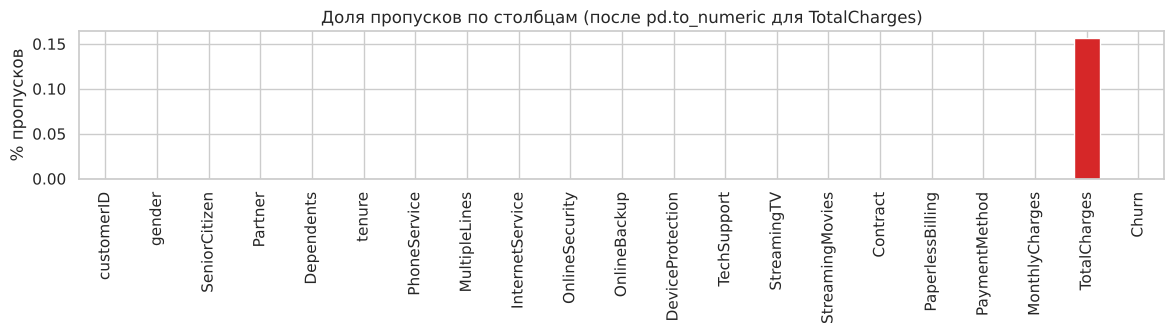

In [6]:
# ===== Анализ пропусков =====
# Явных NaN в файле нет, но TotalCharges хранится строкой, и у части клиентов там пробел ' '
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   # ' ' → NaN
missing = df.isna().sum()                                                   # число пропусков по столбцам
print('Пропуски после приведения TotalCharges к числу:')
print(missing[missing > 0])

# Кто эти клиенты? Смотрим их tenure и Churn
nan_rows = df[df['TotalCharges'].isna()]
print('\ntenure у клиентов с пропуском:', nan_rows['tenure'].unique())
print('Churn у клиентов с пропуском:  ', nan_rows['Churn'].value_counts().to_dict())

# Визуализация пропусков: доля по каждому столбцу
fig, ax = plt.subplots(figsize=(12, 3.5))
(df.isna().mean() * 100).plot(kind='bar', color=['tab:red' if v > 0 else 'tab:gray' for v in df.isna().mean()], ax=ax)
ax.set_ylabel('% пропусков')
ax.set_title('Доля пропусков по столбцам (после pd.to_numeric для TotalCharges)')
plt.tight_layout()
plt.show()

In [7]:
# ===== Анализ целевой переменной =====
print(df['Churn'].value_counts())                            # абсолютные значения
print((df['Churn'].value_counts(normalize=True) * 100).round(1))  # доли в %
# Кодируем целевую в бинарный вид: Yes → 1, No → 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
print('\nДоля ушедших (Churn=1):', round(df['Churn'].mean(), 4))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

Доля ушедших (Churn=1): 0.2654


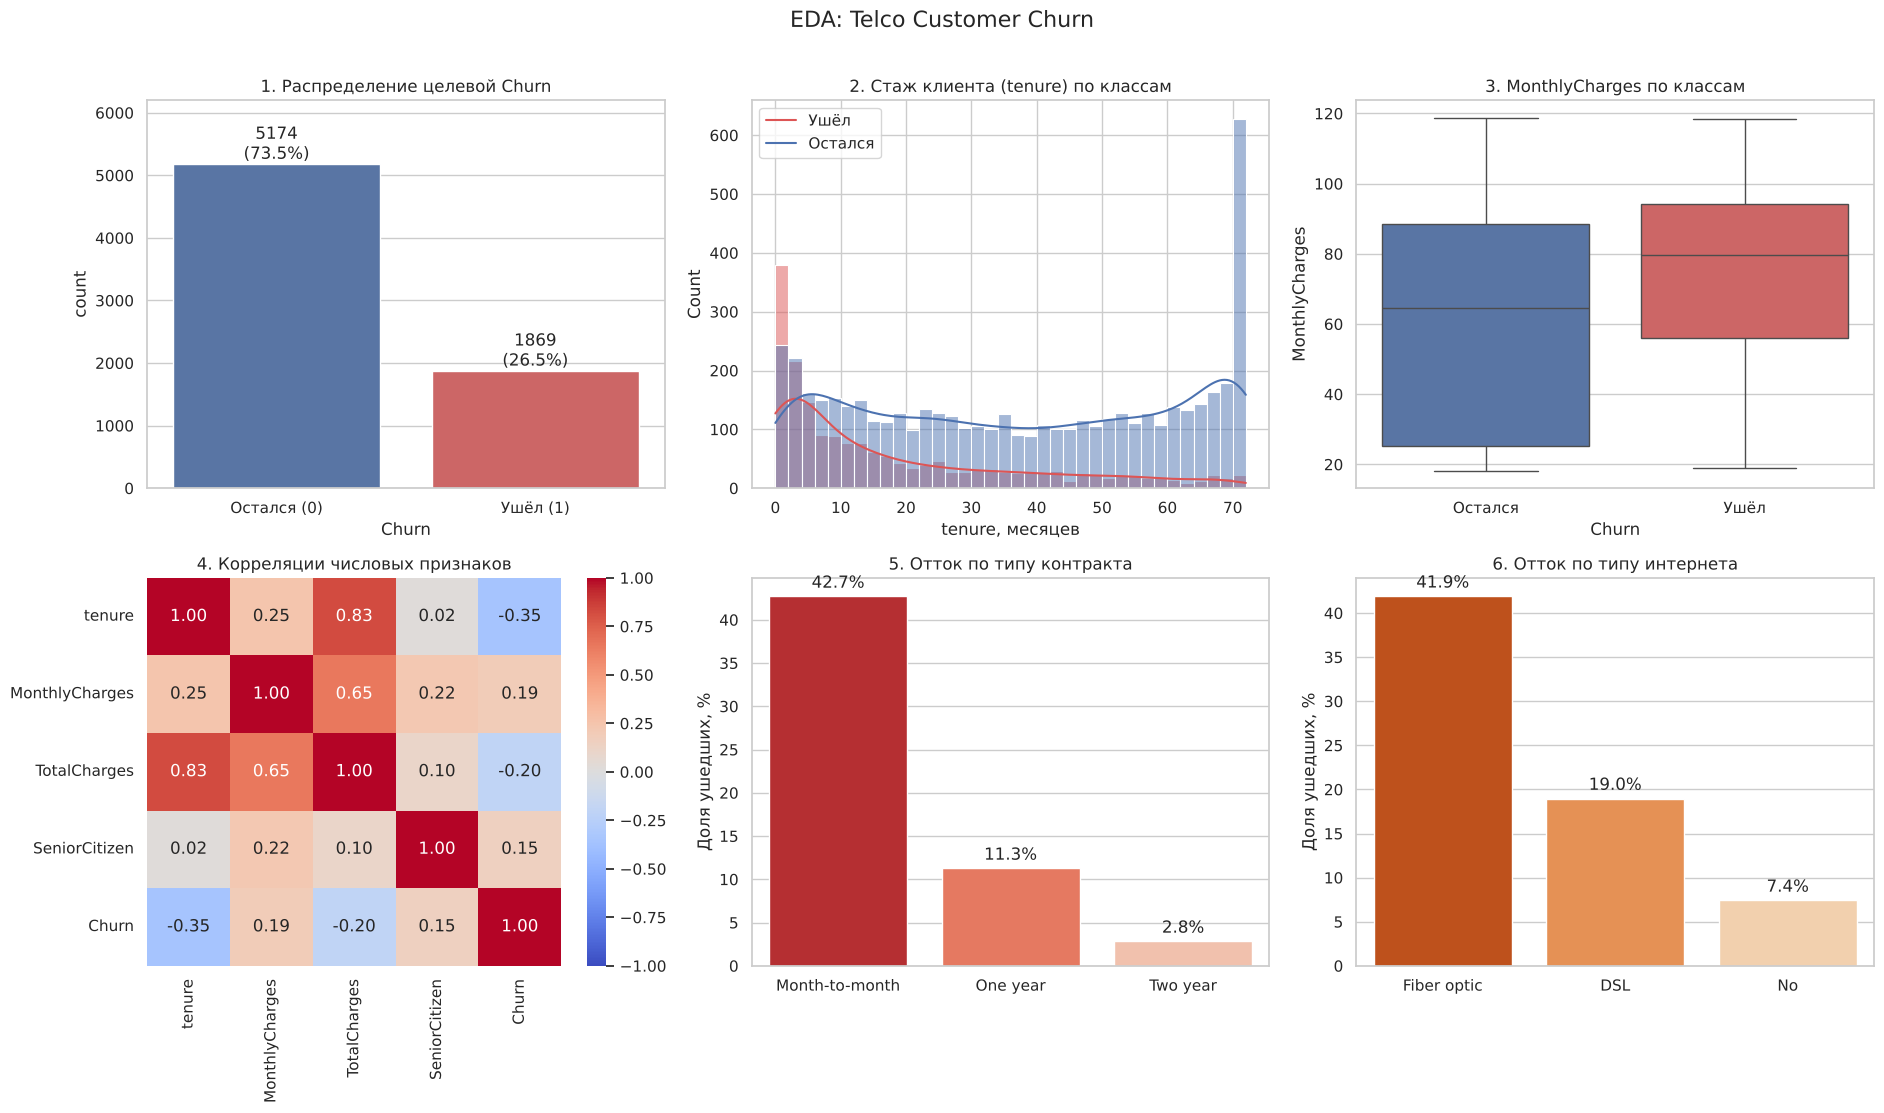

In [8]:
# ===== EDA: сетка из 6 графиков (сохраняется в examples/eda_plots.png) =====
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
churn_lbl = {0: 'Остался', 1: 'Ушёл'}                        # подписи классов
pal = {0: '#4C72B0', 1: '#DD5555'}                           # единые цвета классов

# 1) Countplot целевой
ax = axes[0, 0]
sns.countplot(data=df, x='Churn', hue='Churn', palette=pal, legend=False, ax=ax)
for p in ax.patches:                                          # подписываем доли над столбцами
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.0f}\n({p.get_height()/len(df):.1%})',
                    (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Остался (0)', 'Ушёл (1)'])
ax.set_ylim(0, 6200)
ax.set_title('1. Распределение целевой Churn')

# 2) Гистограмма tenure по классам
ax = axes[0, 1]
sns.histplot(data=df, x='tenure', hue='Churn', palette=pal, bins=36, kde=True, alpha=0.5, ax=ax)
ax.set_title('2. Стаж клиента (tenure) по классам')
ax.set_xlabel('tenure, месяцев'); ax.legend(['Ушёл', 'Остался'])

# 3) Boxplot ежемесячной платы
ax = axes[0, 2]
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette=pal, legend=False, ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Остался', 'Ушёл'])
ax.set_title('3. MonthlyCharges по классам')

# 4) Корреляционная матрица числовых признаков (+ целевая)
ax = axes[1, 0]
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('4. Корреляции числовых признаков')

# 5) Доля ушедших по типу контракта
ax = axes[1, 1]
rate_contract = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
sns.barplot(x=rate_contract.index, y=rate_contract.values * 100, hue=rate_contract.index,
            palette='Reds_r', legend=False, ax=ax)
for i, v in enumerate(rate_contract.values):                  # подписи процентов
    ax.text(i, v * 100 + 1, f'{v:.1%}', ha='center')
ax.set_ylabel('Доля ушедших, %'); ax.set_xlabel('')
ax.set_title('5. Отток по типу контракта')

# 6) Доля ушедших по типу интернета
ax = axes[1, 2]
rate_inet = df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False)
sns.barplot(x=rate_inet.index, y=rate_inet.values * 100, hue=rate_inet.index,
            palette='Oranges_r', legend=False, ax=ax)
for i, v in enumerate(rate_inet.values):
    ax.text(i, v * 100 + 1, f'{v:.1%}', ha='center')
ax.set_ylabel('Доля ушедших, %'); ax.set_xlabel('')
ax.set_title('6. Отток по типу интернета')

plt.suptitle('EDA: Telco Customer Churn', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')   # сохраняем для README
plt.show()

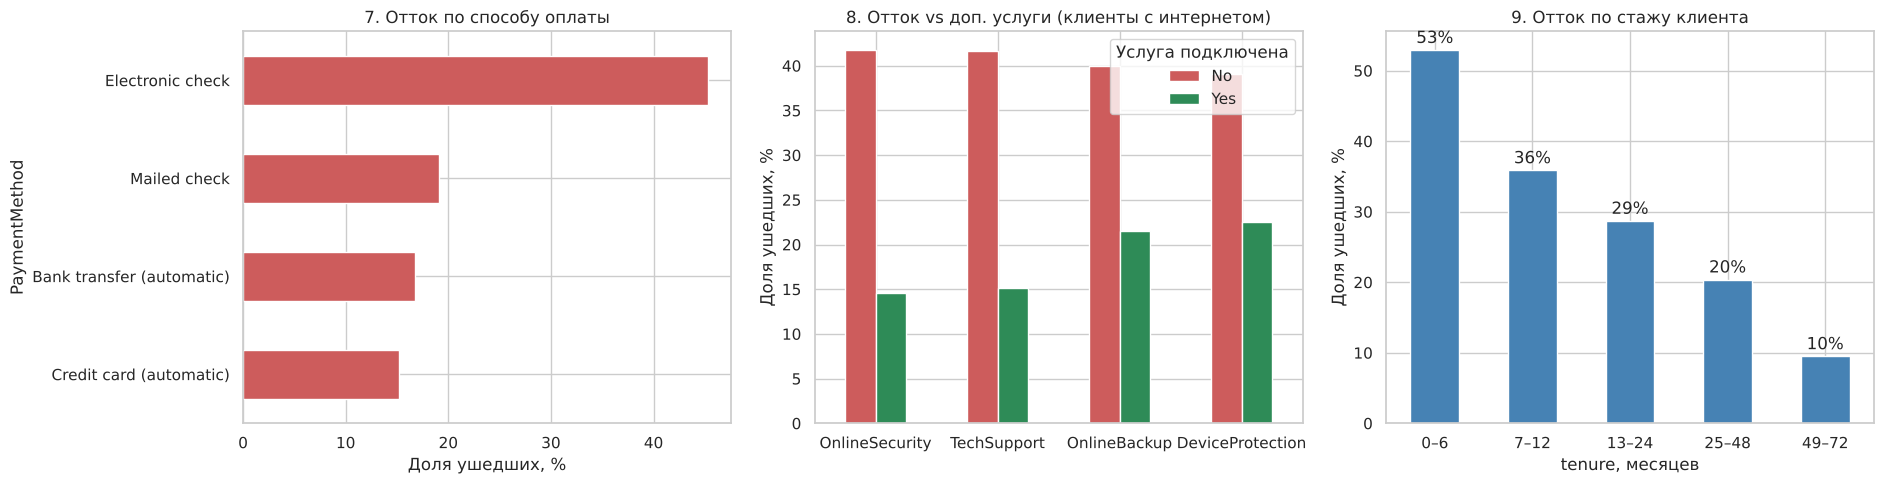

In [9]:
# ===== Дополнительные графики: способ оплаты, доп. услуги, пенсионеры =====
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 7) Отток по способу оплаты
rate_pay = df.groupby('PaymentMethod')['Churn'].mean().sort_values(ascending=False) * 100
rate_pay.plot(kind='barh', color='indianred', ax=axes[0])
axes[0].invert_yaxis(); axes[0].set_xlabel('Доля ушедших, %')
axes[0].set_title('7. Отток по способу оплаты')

# 8) Отток в зависимости от наличия защитных услуг (только у клиентов с интернетом)
inet = df[df['InternetService'] != 'No']                       # у кого нет интернета — услуги недоступны
svc_rates = pd.DataFrame({s: inet.groupby(s)['Churn'].mean() * 100
                          for s in ['OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection']}).T
svc_rates[['No', 'Yes']].plot(kind='bar', color=['indianred', 'seagreen'], ax=axes[1], rot=0)
axes[1].set_ylabel('Доля ушедших, %'); axes[1].legend(title='Услуга подключена')
axes[1].set_title('8. Отток vs доп. услуги (клиенты с интернетом)')

# 9) Отток по группам стажа
bins = [-1, 6, 12, 24, 48, 72]                                  # границы групп tenure
labels = ['0–6', '7–12', '13–24', '25–48', '49–72']
rate_ten = df.groupby(pd.cut(df['tenure'], bins=bins, labels=labels), observed=True)['Churn'].mean() * 100
rate_ten.plot(kind='bar', color='steelblue', ax=axes[2], rot=0)
for i, v in enumerate(rate_ten.values):
    axes[2].text(i, v + 1, f'{v:.0f}%', ha='center')
axes[2].set_xlabel('tenure, месяцев'); axes[2].set_ylabel('Доля ушедших, %')
axes[2].set_title('9. Отток по стажу клиента')

plt.tight_layout()
plt.show()

### 5.1 Выводы EDA
- **Целевая:** 26.5% ушедших — умеренный дисбаланс; нужна стратификация и веса классов.
- **tenure** — самый «говорящий» числовой признак: ушедшие клиенты в основном новые (медиана ≈ 10 мес. против ≈ 38 у оставшихся). В группе 0–6 месяцев уходит **52.9%** клиентов, после 4 лет — меньше 10%.
- **MonthlyCharges:** ушедшие платят в среднем больше (медиана ≈ \$80 против ≈ \$65) — дорогие тарифы (оптоволокно + стриминг) увеличивают отток.
- **Корреляции:** `TotalCharges` сильно коррелирует с `tenure` (0.83) и `MonthlyCharges` (0.65) — это почти их произведение. Для деревьев мультиколлинеарность не критична, но важность «размазывается» между этими признаками. С целевой сильнее всего связан `tenure` (−0.35).
- **Contract** — самый сильный категориальный фактор: месячный контракт → **42.7%** оттока, годовой → **11.3%**, двухлетний → **2.8%**.
- **InternetService:** у клиентов с оптоволокном отток ≈ 42% — вдвое выше, чем у DSL (≈ 19%); без интернета — ≈ 7%.
- **Электронный чек** как способ оплаты — отток ≈ 45%, у автоплатежей — ≈ 15–17%.
- Отсутствие **OnlineSecurity / TechSupport** почти удваивает отток среди интернет-клиентов.

In [10]:
# ===== Обработка пропусков =====
# 11 клиентов с пустым TotalCharges имеют tenure = 0: это новые клиенты, которым ещё не выставлен первый счёт.
# Стратегия по заданию — медиана. Пропусков всего 0.16%, поэтому выбор стратегии почти не влияет на модель;
# медиана устойчива к выбросам (распределение TotalCharges сильно скошено вправо, среднее > медианы).
tc_median = df['TotalCharges'].median()                       # медиана по всем клиентам
df['TotalCharges'] = df['TotalCharges'].fillna(tc_median)     # заполняем пропуски
print(f'Медиана TotalCharges = {tc_median:.2f}')
print('Пропусков осталось:', int(df.isna().sum().sum()))

Медиана TotalCharges = 1397.47
Пропусков осталось: 0


**Обоснование стратегии.** Удалять строки не стали — это реальные клиенты, а модель должна уметь работать и с новыми клиентами. Заполнение **медианой** (а не средним) выбрано потому, что `TotalCharges` сильно скошен вправо (среднее ≈ 2283, медиана ≈ 1397) и среднее смещено «хвостом» дорогих долгосрочных клиентов. Логически для `tenure = 0` правильнее было бы поставить 0 (клиент ещё ничего не заплатил), но таких строк всего 11 из 7043 — на качество модели это не влияет; для инференса значение медианы сохранено в `models/preprocess_meta.json`.

In [11]:
# ===== Feature Engineering =====
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    """Создаёт 4 новых признака. Применяется одинаково к обучающим и к новым данным."""
    data = data.copy()
    data['TenureYears'] = data['tenure'] / 12                                   # стаж в годах
    data['AvgMonthlyCharge'] = data['TotalCharges'] / (data['tenure'] + 1)      # средний фактический платёж (+1 от деления на 0)
    data['IsNewClient'] = (data['tenure'] <= 6).astype(int)                     # новичок: первые полгода — зона риска
    # Счётчик подключённых услуг: телефонные/доп. услуги со значением 'Yes' + сам интернет
    data['HasMultipleServices'] = ((data[service_cols] == 'Yes').sum(axis=1)
                                   + (data['InternetService'] != 'No').astype(int))
    return data

df = add_features(df)                                         # применяем к датасету
new_feats = ['TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']
display(df[new_feats + ['Churn']].describe().round(2))

# Как новые признаки связаны с оттоком
print('Доля ушедших среди новичков (IsNewClient=1):', round(df.loc[df.IsNewClient == 1, 'Churn'].mean(), 3))
print('Доля ушедших среди остальных (IsNewClient=0):', round(df.loc[df.IsNewClient == 0, 'Churn'].mean(), 3))
print('\nДоля ушедших по числу услуг:')
print(df.groupby('HasMultipleServices')['Churn'].agg(['mean', 'size']).round(3).T)

,TenureYears,AvgMonthlyCharge,IsNewClient,HasMultipleServices,Churn
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,2.70,61.17,0.21,4.15,0.27
std,2.05,61.02,0.41,2.31,0.44
min,0.00,9.18,0.00,1.00,0.00
25%,0.75,26.27,0.00,2.00,0.00
50%,2.42,61.15,0.00,4.00,0.00
75%,4.58,84.94,0.00,6.00,1.00
max,6.00,1397.48,1.00,9.00,1.00


Доля ушедших среди новичков (IsNewClient=1): 0.529
Доля ушедших среди остальных (IsNewClient=0): 0.195

Доля ушедших по числу услуг:
HasMultipleServices         1       2        3        4        5        6  \
mean                    0.109    0.31    0.449    0.365    0.313    0.256   
size                 1264.000  859.00  846.000  965.000  922.000  908.000   

HasMultipleServices        7        8        9  
mean                   0.225    0.124    0.053  
size                 676.000  395.000  208.000  


**Зачем эти признаки:**
- `TenureYears` — та же информация, что `tenure`, в удобной для интерпретации шкале (для деревьев эквивалентна `tenure`; оставлена по заданию).
- `AvgMonthlyCharge` — средний *фактический* платёж за всё время. Если он заметно отличается от текущего `MonthlyCharges`, значит, тариф недавно меняли (повышение цены — повод уйти).
- `IsNewClient` — явный флаг «первые 6 месяцев»: в этой группе отток более 50%.
- `HasMultipleServices` — «глубина» вовлечённости клиента: чем больше услуг подключено, тем выше стоимость перехода к конкуренту. Зависимость немонотонная: клиенты с одной услугой (только телефон, без интернета) уходят редко, а пик оттока — у клиентов с 2–3 услугами, обычно «голое» оптоволокно без допов.

In [12]:
# ===== Кодирование категориальных признаков =====
# Churn уже переведён в 0/1. Все строковые признаки кодируем LabelEncoder'ом:
# деревьям не нужен One-Hot — они сами находят нужные пороги по коду категории.
cat_features = [c for c in df.select_dtypes(exclude='number').columns if c != 'customerID']
label_encoders = {}                                           # словарь кодировщиков (сохраним в .pkl)
for col in cat_features:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])                       # строка → целое число
    label_encoders[col] = le                                  # запоминаем для инференса
    print(f'{col:<18} → {dict(zip(le.classes_, le.transform(le.classes_)))}')
print(f'\nЗакодировано признаков: {len(cat_features)}')

gender             → {'Female': np.int64(0), 'Male': np.int64(1)}
Partner            → {'No': np.int64(0), 'Yes': np.int64(1)}
Dependents         → {'No': np.int64(0), 'Yes': np.int64(1)}
PhoneService       → {'No': np.int64(0), 'Yes': np.int64(1)}
MultipleLines      → {'No': np.int64(0), 'No phone service': np.int64(1), 'Yes': np.int64(2)}
InternetService    → {'DSL': np.int64(0), 'Fiber optic': np.int64(1), 'No': np.int64(2)}
OnlineSecurity     → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
OnlineBackup       → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
DeviceProtection   → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
TechSupport        → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
StreamingTV        → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
StreamingMovies    → {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes':

In [13]:
# ===== Формирование X, y и разбиение train/test =====
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]   # 19 исходных + 4 новых
X = df[feature_cols]
y = df['Churn']

# stratify=y — сохраняем долю ушедших (26.5%) и в train, и в test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Признаков: {len(feature_cols)}')
print(f'Train: {X_train.shape}, доля Churn=1: {y_train.mean():.3f}')
print(f'Test:  {X_test.shape},  доля Churn=1: {y_test.mean():.3f}')

# Масштабирование нужно только линейной модели-ориентиру (деревьям — нет).
# Scaler обучаем ТОЛЬКО на train, чтобы не было утечки информации из test.
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

Признаков: 23
Train: (5634, 23), доля Churn=1: 0.265
Test:  (1409, 23),  доля Churn=1: 0.265


## Построение и обучение моделей

Обучаем 4 обязательные ансамблевые модели с параметрами из задания. Для каждой фиксируем время обучения. Дисбаланс компенсируем весами классов: `class_weight='balanced'` (RF, LightGBM), `scale_pos_weight=3` (XGBoost, ≈ 5174/1869 = 2.77), `auto_class_weights='Balanced'` (CatBoost).

Дополнительно, чтобы ответить на вопрос «зачем ансамбли», обучаем две одиночные модели-ориентира: **дерево решений** и **логистическую регрессию** (на масштабированных признаках).

In [14]:
# ===== Функция для обучения с замером времени =====
train_times = {}                                              # сюда пишем время обучения каждой модели

def fit_timed(model, name, Xtr=X_train, ytr=y_train):
    """Обучает модель и печатает время обучения."""
    start = time.time()
    model.fit(Xtr, ytr)
    train_times[name] = time.time() - start                   # секунды
    print(f'⏱️ Время обучения {name:<15}: {train_times[name]:.3f} сек')
    return model

In [15]:
# ===== 1. Random Forest (bagging) =====
rf_model = RandomForestClassifier(
    n_estimators=200,             # 200 деревьев
    max_depth=10,                 # ограничиваем глубину, чтобы деревья не запоминали шум
    class_weight='balanced',      # веса классов обратно пропорциональны их частоте
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model = fit_timed(rf_model, 'Random Forest')

# ===== 2. XGBoost (boosting) =====
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,      # стохастичность: 90% строк и признаков на дерево
    scale_pos_weight=3,                       # компенсация дисбаланса (≈ 5174/1869)
    random_state=RANDOM_STATE, eval_metric='logloss'
)
xgb_model = fit_timed(xgb_model, 'XGBoost')

# ===== 3. LightGBM (boosting) =====
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=RANDOM_STATE, verbose=-1    # verbose=-1 — без служебного вывода
)
lgbm_model = fit_timed(lgbm_model, 'LightGBM')

# ===== 4. CatBoost (boosting) =====
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced',            # аналог class_weight='balanced'
    random_state=RANDOM_STATE, verbose=0
)
cat_model = fit_timed(cat_model, 'CatBoost')

⏱️ Время обучения Random Forest  : 0.804 сек


⏱️ Время обучения XGBoost        : 0.201 сек
⏱️ Время обучения LightGBM       : 0.195 сек


⏱️ Время обучения CatBoost       : 0.481 сек


In [16]:
# ===== Модели-ориентиры (одиночные) =====
# Одиночное глубокое дерево: такое же, как в лесу, но одно
tree_model = fit_timed(DecisionTreeClassifier(max_depth=10, class_weight='balanced',
                                              random_state=RANDOM_STATE), 'Decision Tree')
# Логистическая регрессия на масштабированных признаках
lr_model = fit_timed(LogisticRegression(max_iter=2000, class_weight='balanced'),
                     'LogReg', Xtr=X_train_sc)

⏱️ Время обучения Decision Tree  : 0.030 сек
⏱️ Время обучения LogReg         : 0.022 сек


In [17]:
# ===== Сводная таблица моделей (время подставляется автоматически) =====
models_info = [
    ('Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced'),
    ('XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3'),
    ('LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05'),
    ('CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced'),
    ('Decision Tree', 'Одиночная (ориентир)', 'max_depth=10'),
    ('LogReg',        'Одиночная (ориентир)', 'StandardScaler + class_weight=balanced'),
]
table = '| Модель | Тип | Параметры | Время обучения |\n|---|---|---|---|\n'
table += '\n'.join(f'| {n} | {t} | {p} | {train_times[n]:.3f} сек |' for n, t, p in models_info)
display(Markdown(table))

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight=balanced | 0.804 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3 | 0.201 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, max_depth=7, lr=0.05 | 0.195 сек |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced | 0.481 сек |
| Decision Tree | Одиночная (ориентир) | max_depth=10 | 0.030 сек |
| LogReg | Одиночная (ориентир) | StandardScaler + class_weight=balanced | 0.022 сек |

## Модели

**Почему эти модели:**
- **Random Forest** — устойчив к переобучению и шуму, работает «из коробки», даёт надёжную точку отсчёта для ансамблей.
- **XGBoost** — универсальный и точный бустинг с явной регуляризацией ($L_1$/$L_2$), стандарт индустрии на табличных данных.
- **LightGBM** — самый быстрый бустинг (гистограммы + leaf-wise рост), удобен для многократного обучения — поэтому именно его тюним в Optuna (50 испытаний × 5 фолдов = 250 обучений).
- **CatBoost** — лучший для категориальных признаков (а у нас их 16 из 19) и устойчив с параметрами по умолчанию.

**Время обучения.** Из таблицы выше: LightGBM и XGBoost обучаются за доли секунды; CatBoost медленнее (симметричные деревья + ordered boosting на CPU); Random Forest — самый медленный из ансамблей, т.к. строит 200 *глубоких* деревьев (бустинг — 200 неглубоких). Одиночные модели обучаются мгновенно. На 5.6 тыс. строк все модели укладываются в 1–2 секунды, поэтому скорость здесь не решающий фактор, но при миллионах строк разница LightGBM vs RF/CatBoost становится существенной.

## Оценка качества

Считаем 5 метрик на отложенной тестовой выборке (1409 клиентов, порог 0.5) + ROC-AUC на 5-фолдовой кросс-валидации по train, чтобы оценить устойчивость: разница между моделями на одном тесте может быть случайной.

In [18]:
# ===== Функция расчёта метрик =====
def evaluate_model(model, X_test, y_test, name):
    """Возвращает словарь метрик для модели на тестовой выборке."""
    y_pred = model.predict(X_test)                            # метки при пороге 0.5
    y_proba = model.predict_proba(X_test)[:, 1]               # вероятность класса «ушёл»
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba),
    }

# 4 обязательные модели
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost'),
]
# Ориентиры (одиночные модели) — отдельным списком, чтобы results остался из 4 ансамблей
baselines = [
    evaluate_model(tree_model, X_test, y_test, 'Decision Tree'),
    evaluate_model(lr_model, X_test_sc, y_test, 'LogReg'),
]
results_df = pd.DataFrame(results + baselines)
results_df['Время, с'] = results_df['Model'].map(train_times)
print(results_df.round(4).to_string(index=False))

        Model  Accuracy  Precision  Recall     F1  ROC-AUC  Время, с
Random Forest    0.7601     0.5346  0.7433 0.6219   0.8388    0.8040
      XGBoost    0.7630     0.5417  0.6952 0.6089   0.8279    0.2014
     LightGBM    0.7594     0.5332  0.7513 0.6238   0.8377    0.1949
     CatBoost    0.7488     0.5187  0.7433 0.6110   0.8409    0.4814
Decision Tree    0.7197     0.4809  0.7086 0.5730   0.7430    0.0300
       LogReg    0.7424     0.5095  0.7861 0.6183   0.8465    0.0221


In [19]:
# ===== Устойчивость: ROC-AUC на 5-fold CV (только train) =====
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = {}
for model, name in [(rf_model, 'Random Forest'), (xgb_model, 'XGBoost'),
                    (lgbm_model, 'LightGBM'), (cat_model, 'CatBoost'), (tree_model, 'Decision Tree')]:
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='roc_auc')   # 5 обучений
    cv_auc[name] = scores
    print(f'{name:<14} CV ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}')
results_df['CV ROC-AUC'] = results_df['Model'].map(lambda n: cv_auc[n].mean() if n in cv_auc else np.nan)

Random Forest  CV ROC-AUC = 0.8429 ± 0.0092


XGBoost        CV ROC-AUC = 0.8340 ± 0.0076


LightGBM       CV ROC-AUC = 0.8401 ± 0.0090


CatBoost       CV ROC-AUC = 0.8378 ± 0.0090
Decision Tree  CV ROC-AUC = 0.7372 ± 0.0096


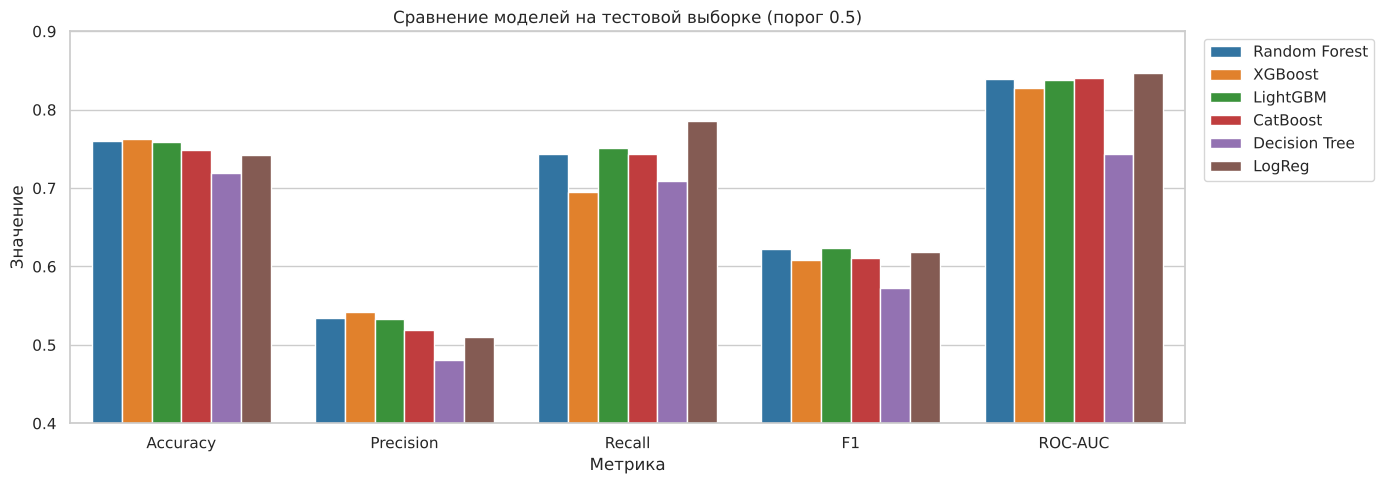

In [20]:
# ===== Визуальное сравнение метрик =====
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
plot_df = results_df.melt(id_vars='Model', value_vars=metric_names, var_name='Метрика', value_name='Значение')
plt.figure(figsize=(14, 5))
sns.barplot(data=plot_df, x='Метрика', y='Значение', hue='Model', palette='tab10')
plt.ylim(0.4, 0.9)
plt.title('Сравнение моделей на тестовой выборке (порог 0.5)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

Лучшая модель по ROC-AUC на тесте: CatBoost


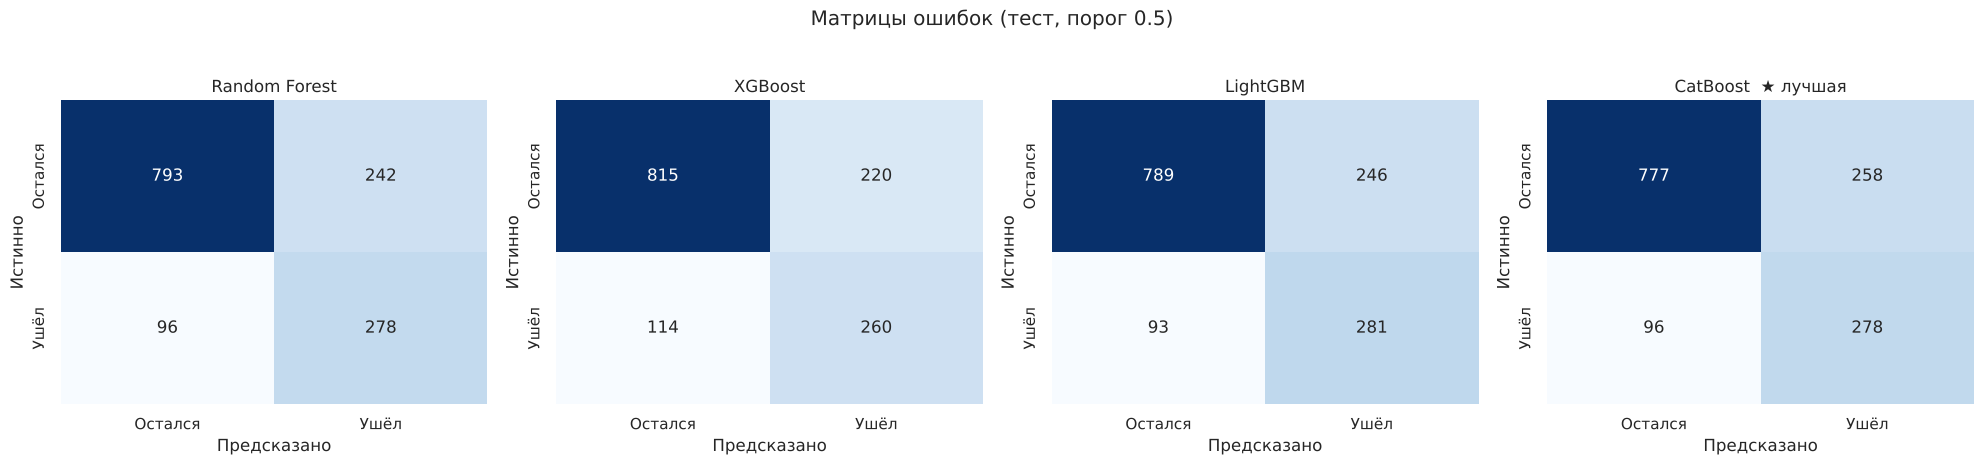

              precision    recall  f1-score   support

     Остался      0.890     0.751     0.814      1035
        Ушёл      0.519     0.743     0.611       374

    accuracy                          0.749      1409
   macro avg      0.704     0.747     0.713      1409
weighted avg      0.791     0.749     0.760      1409



In [21]:
# ===== Матрицы ошибок 4 ансамблей; лучшая модель — по ROC-AUC =====
ens_models = {'Random Forest': rf_model, 'XGBoost': xgb_model, 'LightGBM': lgbm_model, 'CatBoost': cat_model}
best_name = max(results, key=lambda r: r['ROC-AUC'])['Model']    # лучшая по ROC-AUC
print('Лучшая модель по ROC-AUC на тесте:', best_name)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, ens_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))         # [[TN, FP], [FN, TP]]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
    ax.set_xlabel('Предсказано'); ax.set_ylabel('Истинно')
    ax.set_title(name + ('  ★ лучшая' if name == best_name else ''))
plt.suptitle('Матрицы ошибок (тест, порог 0.5)', y=1.03)
plt.tight_layout()
plt.savefig('examples/confusion_matrices.png', dpi=110, bbox_inches='tight')
plt.show()

# Подробный отчёт по лучшей модели
y_pred_best_base = ens_models[best_name].predict(X_test)
print(classification_report(y_test, y_pred_best_base, target_names=['Остался', 'Ушёл'], digits=3))

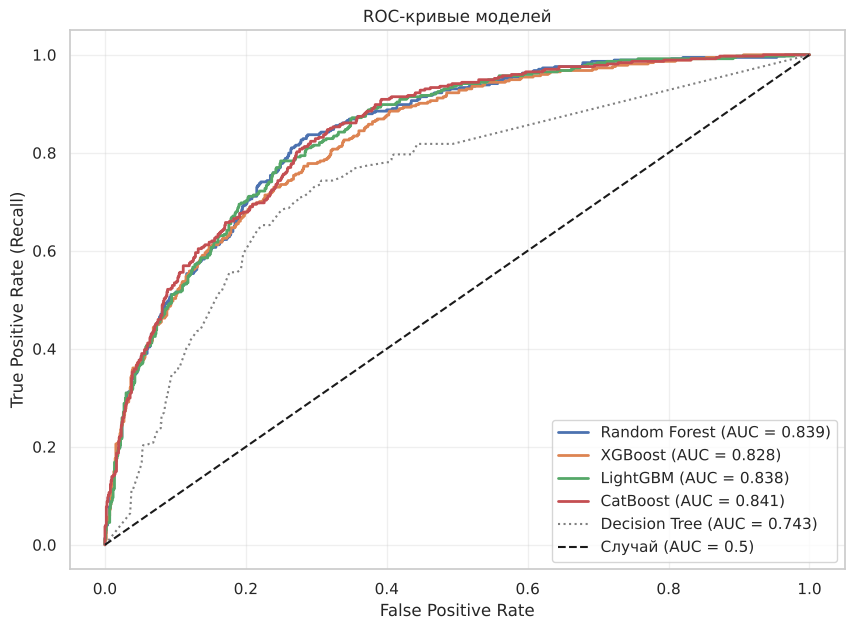

In [22]:
# ===== ROC-кривые всех 4 моделей на одном графике =====
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'Random Forest'), (xgb_model, 'XGBoost'),
                    (lgbm_model, 'LightGBM'), (cat_model, 'CatBoost')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)                   # точки кривой при всех порогах
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)
# Для сравнения — одиночное дерево пунктиром
fpr, tpr, _ = roc_curve(y_test, tree_model.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, ':', color='gray', label=f'Decision Tree (AUC = {roc_auc_score(y_test, tree_model.predict_proba(X_test)[:, 1]):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=110, bbox_inches='tight')
plt.show()

In [23]:
# ===== Итоговая таблица в Markdown (числа подставляются из results_df) =====
t = '| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | CV ROC-AUC | Время, с |\n|---|---|---|---|---|---|---|---|\n'
for _, r in results_df.iterrows():
    t += (f"| {r['Model']} | {r['Accuracy']:.3f} | {r['Precision']:.3f} | {r['Recall']:.3f} | "
          f"{r['F1']:.3f} | {r['ROC-AUC']:.3f} | {r['CV ROC-AUC']:.3f} | {r['Время, с']:.2f} |\n")
display(Markdown(t))

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | CV ROC-AUC | Время, с |
|---|---|---|---|---|---|---|---|
| Random Forest | 0.760 | 0.535 | 0.743 | 0.622 | 0.839 | 0.843 | 0.80 |
| XGBoost | 0.763 | 0.542 | 0.695 | 0.609 | 0.828 | 0.834 | 0.20 |
| LightGBM | 0.759 | 0.533 | 0.751 | 0.624 | 0.838 | 0.840 | 0.19 |
| CatBoost | 0.749 | 0.519 | 0.743 | 0.611 | 0.841 | 0.838 | 0.48 |
| Decision Tree | 0.720 | 0.481 | 0.709 | 0.573 | 0.743 | 0.737 | 0.03 |
| LogReg | 0.742 | 0.510 | 0.786 | 0.618 | 0.847 | nan | 0.02 |


**Анализ:**
- **Лучшая модель по ROC-AUC на тесте — CatBoost** (AUC = 0.841); но все 4 ансамбля лежат в узком коридоре **0.828–0.841**, а разброс между фолдами CV (± 0.01) того же порядка. Значит, на этих данных модели **практически равноценны** — сигнал в данных ограничен, и выбор модели важен меньше, чем признаки и порог.
- По кросс-валидации лидеры — Random Forest (0.843) и LightGBM (0.840); **XGBoost** с параметрами из задания (глубина 6, lr = 0.1) немного переобучается и отстаёт.
- **Ансамбли vs одиночное дерево:** дерево той же глубины, что в лесу, даёт заметно худший AUC (**0.743**) — усреднение 200 таких деревьев в Random Forest поднимает AUC почти на 0.1. Это наглядно показывает, как bagging гасит дисперсию.
- **Честное наблюдение: логистическая регрессия (0.847) на тесте не хуже базовых ансамблей.** Зависимость оттока от признаков в Telco в основном монотонная (меньше стаж → выше риск, месячный контракт → выше риск), сложных взаимодействий мало, поэтому линейная модель уже близка к потолку. Ансамбли с параметрами «по умолчанию» слегка переобучаются; обогнать линейную модель удаётся только после тюнинга (раздел 9).
- **LightGBM** — один из самых быстрых (≈ 0.1–0.3 c) при качестве на уровне лидеров, поэтому он и выбран для тюнинга в Optuna.
- **Recall выше Precision** у всех ансамблей: благодаря весам классов модели «агрессивно» помечают клиентов как уходящих — находят ≈ 70–75% реально ушедших, но примерно половина тревог ложные. Для задачи удержания это осознанный выбор: звонок лояльному клиенту стоит дешевле, чем потерянный абонент. Если бюджет удержания мал, порог можно поднять (см. калибровку в разделе 9).
- **Accuracy** (≈ 0.75–0.76) лишь немного выше «наивных» 73.5% (всем ответить «останется») — потому что модели сознательно жертвуют точностью на большинстве ради нахождения меньшинства. При этом «наивная» модель не находит ни одного уходящего, а наши — три из четырёх. Это ещё раз показывает, почему Accuracy здесь — плохая метрика.

## Интерпретация и бизнес-инсайты

Смотрим встроенную важность признаков у Random Forest (среднее уменьшение неоднородности Джини) и LightGBM. У LightGBM по умолчанию важность = **число разбиений** (`split`), что завышает непрерывные признаки с множеством порогов; поэтому дополнительно строим важность по **приросту качества** (`gain`).

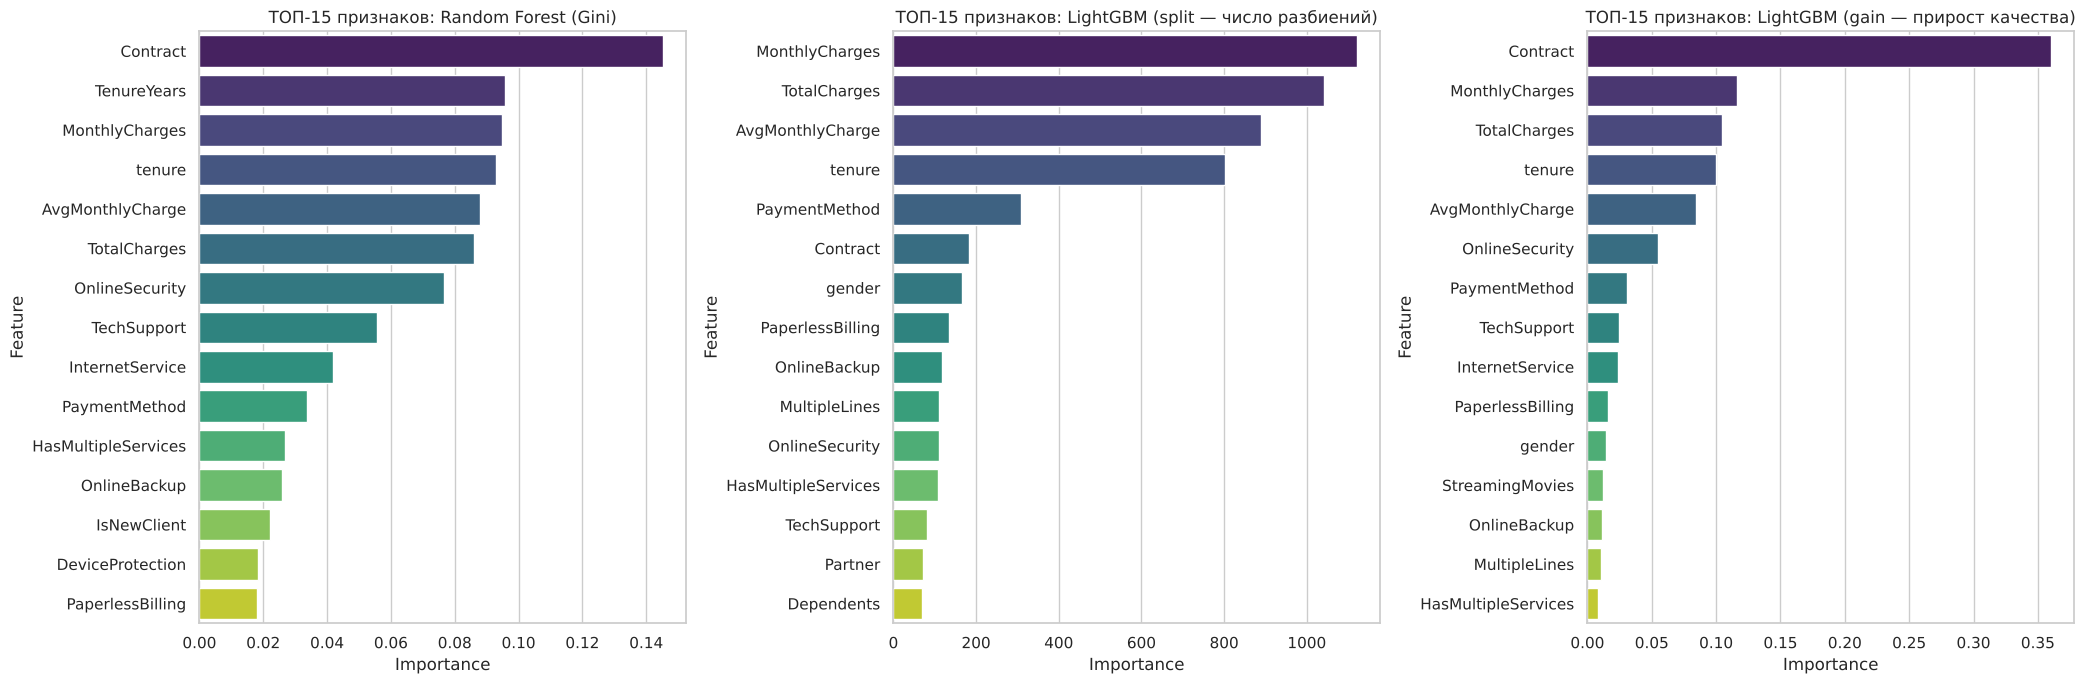

Топ-5 RF:           ['Contract', 'TenureYears', 'MonthlyCharges', 'tenure', 'AvgMonthlyCharge']
Топ-5 LGBM (split): ['MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'tenure', 'PaymentMethod']
Топ-5 LGBM (gain):  ['Contract', 'MonthlyCharges', 'TotalCharges', 'tenure', 'AvgMonthlyCharge']


In [24]:
# ===== Feature Importance: RF (Gini) и LightGBM (split и gain) =====
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)
importances = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)                       # split-важность LightGBM
gain = lgbm_model.booster_.feature_importance(importance_type='gain')        # gain-важность LightGBM
imp_gain = pd.DataFrame({'Feature': feature_cols, 'Importance': gain / gain.sum()}) \
           .sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
sns.barplot(data=imp_rf.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('ТОП-15 признаков: Random Forest (Gini)')
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('ТОП-15 признаков: LightGBM (split — число разбиений)')
sns.barplot(data=imp_gain.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[2])
axes[2].set_title('ТОП-15 признаков: LightGBM (gain — прирост качества)')
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=110, bbox_inches='tight')
plt.show()

print('Топ-5 RF:          ', imp_rf['Feature'].head(5).tolist())
print('Топ-5 LGBM (split):', importances['Feature'].head(5).tolist())
print('Топ-5 LGBM (gain): ', imp_gain['Feature'].head(5).tolist())

In [25]:
# ===== Бизнес-цифры: доля оттока по ключевым сегментам (исходные категории) =====
seg = df_raw.copy()
seg['Churn'] = (seg['Churn'] == 'Yes').astype(int)
seg['tenure_group'] = pd.cut(seg['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                             labels=['0–6 мес', '7–12 мес', '1–2 года', '2–4 года', '4–6 лет'])
for col in ['Contract', 'tenure_group', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport']:
    t = seg.groupby(col, observed=True)['Churn'].agg(['mean', 'size']).rename(columns={'mean': 'доля оттока', 'size': 'клиентов'})
    t['доля оттока'] = (t['доля оттока'] * 100).round(1)
    print(f'--- {col} ---'); print(t.sort_values('доля оттока', ascending=False).to_string()); print()

# Во сколько раз месячный контракт рискованнее годового
r = seg.groupby('Contract')['Churn'].mean()
print(f"Месячный / годовой контракт: в {r['Month-to-month'] / r['One year']:.1f} раза больше оттока")
print(f"Месячный / двухлетний:       в {r['Month-to-month'] / r['Two year']:.1f} раз больше оттока")

--- Contract ---
                доля оттока  клиентов
Contract                             
Month-to-month         42.7      3875
One year               11.3      1473
Two year                2.8      1695

--- tenure_group ---
              доля оттока  клиентов
tenure_group                       
0–6 мес              52.9      1481
7–12 мес             35.9       705
1–2 года             28.7      1024
2–4 года             20.4      1594
4–6 лет               9.5      2239

--- InternetService ---
                 доля оттока  клиентов
InternetService                       
Fiber optic             41.9      3096
DSL                     19.0      2421
No                       7.4      1526

--- PaymentMethod ---
                           доля оттока  клиентов
PaymentMethod                                   
Electronic check                  45.3      2365
Mailed check                      19.1      1612
Bank transfer (automatic)         16.7      1544
Credit card (automatic)        

## Интерпретация

**Топ-5 признаков, влияющих на отток** (сводно по RF, LightGBM-gain и SHAP из раздела 10):
1. **Contract** (тип контракта) — самый сильный предиктор: первое место по Gini у RF, по gain у LightGBM и по SHAP.
2. **tenure / TenureYears** (стаж) — чем дольше клиент с компанией, тем меньше риск.
3. **MonthlyCharges / TotalCharges / AvgMonthlyCharge** — финансовая нагрузка; LightGBM по `split` ставит их на первые места, потому что у непрерывных признаков много возможных порогов разбиения (поэтому split-важность и вводит в заблуждение).
4. **OnlineSecurity / TechSupport** — отсутствие защитных услуг (по SHAP `OnlineSecurity` — №2).
5. **InternetService** и **PaymentMethod** — оптоволокно и оплата электронным чеком.

Замечание: `gender`, `PhoneService`, `StreamingTV`, `SeniorCitizen` почти не влияют (нет в топ-15 по SHAP) — модель могла бы обойтись без них. Высокая split-важность `gender` у baseline LightGBM — признак переобучения: модель «нарезает» шум.

**Бизнес-инсайты:**
- Клиенты с **месячным контрактом** уходят в **3.8 раза** чаще, чем с годовым, и в **15 раз** чаще, чем с двухлетним → главный рычаг удержания: скидка за переход на годовой контракт.
- **Первые 6 месяцев — самый рискованный период** (отток ≈ 52.9%); 2–4 года — ≈ 20%, после 4 лет — меньше 10%. Нужна программа онбординга новичков (приветственный звонок, бонус на 3-й и 6-й месяц).
- **Fiber optic** → отток ≈ 42% при более высокой цене: клиенты либо недовольны соотношением цена/качество, либо их активно переманивают конкуренты. Стоит проверить качество сервиса и цены на оптоволокно.
- **Отсутствие OnlineSecurity и TechSupport → рост оттока** почти в 3 раза (≈ 42% против ≈ 15%). Предложить эти услуги бесплатно на 3 месяца — дешёвый способ «привязать» клиента.
- **Электронный чек** → отток ≈ 45% против ≈ 15–17% у автоплатежа; перевод клиентов на автоплатёж (например, с небольшой скидкой) снижает «точки принятия решения» об уходе.
- **Портрет клиента из группы риска:** новый (до полугода), месячный контракт, оптоволокно без доп. услуг, оплата электронным чеком, высокий ежемесячный платёж.

## Тюнинг гиперпараметров (Optuna)

Оптимизируем **LightGBM** — он быстрый (250 обучений займут меньше минуты) и в базовой конфигурации на уровне лидеров. Целевая функция — **средний ROC-AUC на 5-фолдовой стратифицированной CV по train** (тестовую выборку при подборе не трогаем, чтобы не было утечки). Сэмплер — **TPE** с фиксированным `seed` для воспроизводимости, **50 испытаний**.

Замечание: в LightGBM параметр `subsample` (bagging_fraction) работает только при `subsample_freq > 0`, поэтому фиксируем `subsample_freq=1` — иначе Optuna подбирала бы параметр, который ни на что не влияет.

In [26]:
# ===== Optuna: байесовская оптимизация LightGBM =====
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)          # без лога по каждому испытанию

def objective(trial):
    """Целевая функция: средний ROC-AUC на 5-fold CV для набора гиперпараметров."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),    # лог-шкала
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),            # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),          # L2
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1)
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        scoring='roc_auc'
    )
    return cv_scores.mean()

N_TRIALS = 50
start = time.time()
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))   # воспроизводимый TPE
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
optuna_time = time.time() - start

print(f'Испытаний: {len(study.trials)}, время: {optuna_time:.1f} сек')
print(f'Best CV ROC-AUC: {study.best_value:.4f} (испытание №{study.best_trial.number})')
print('Лучшие параметры:')
for key, value in study.best_params.items():
    print(f'  {key}: {round(value, 5) if isinstance(value, float) else value}')

Испытаний: 50, время: 57.5 сек
Best CV ROC-AUC: 0.8500 (испытание №38)
Лучшие параметры:
  n_estimators: 400
  num_leaves: 90
  max_depth: 3
  learning_rate: 0.01541
  subsample: 0.64392
  colsample_bytree: 0.53682
  min_child_samples: 45
  reg_alpha: 0.00589
  reg_lambda: 3.22012


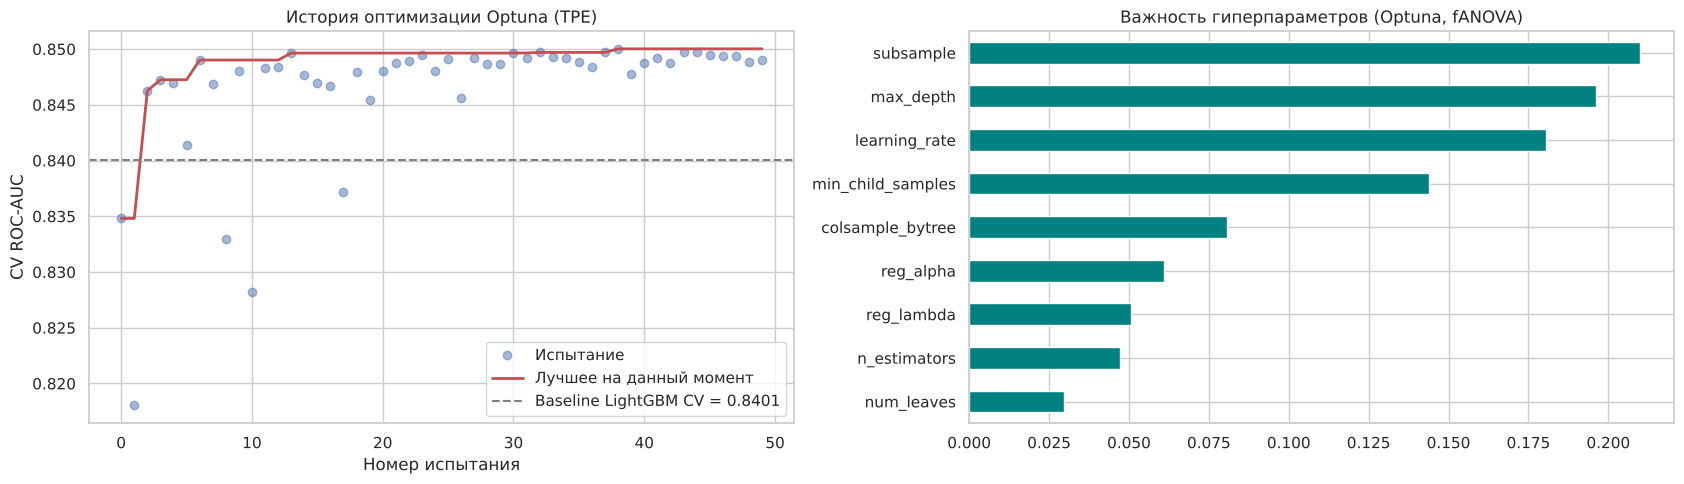

In [27]:
# ===== История оптимизации и важность гиперпараметров =====
trials_df = study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(trials_df['number'], trials_df['value'], 'o', alpha=0.5, label='Испытание')
axes[0].plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')
lgbm_base_cv = cv_auc['LightGBM'].mean()
axes[0].axhline(lgbm_base_cv, color='gray', ls='--', label=f'Baseline LightGBM CV = {lgbm_base_cv:.4f}')
axes[0].set_xlabel('Номер испытания'); axes[0].set_ylabel('CV ROC-AUC')
axes[0].set_title('История оптимизации Optuna (TPE)'); axes[0].legend()

# Важность гиперпараметров (fANOVA): какие параметры сильнее всего влияют на ROC-AUC
param_imp = optuna.importance.get_param_importances(study)
pd.Series(param_imp).sort_values().plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Важность гиперпараметров (Optuna, fANOVA)')
plt.tight_layout()
plt.savefig('examples/optuna_history.png', dpi=110, bbox_inches='tight')
plt.show()

In [28]:
# ===== Обучаем лучшую модель и сравниваем с baseline на тесте =====
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1,
                           class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)
best_lgbm = fit_timed(best_lgbm, 'LightGBM (Optuna)')

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
auc_opt = roc_auc_score(y_test, y_proba_best)
print(f'ROC-AUC baseline (тест): {auc_base:.4f}')
print(f'ROC-AUC Optuna   (тест): {auc_opt:.4f}')
print(f'Прирост: {auc_opt - auc_base:+.4f} ({(auc_opt / auc_base - 1) * 100:+.2f}%)')
print(f'CV ROC-AUC: baseline {lgbm_base_cv:.4f} → Optuna {study.best_value:.4f}')

# Полная строка метрик для таблицы сравнения
res_opt = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')
cmp = pd.DataFrame([r for r in results if r['Model'] == 'LightGBM'] + [res_opt]).set_index('Model')
display(cmp.round(4))

⏱️ Время обучения LightGBM (Optuna): 0.190 сек
ROC-AUC baseline (тест): 0.8377
ROC-AUC Optuna   (тест): 0.8495
Прирост: +0.0118 (+1.41%)
CV ROC-AUC: baseline 0.8401 → Optuna 0.8500


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
LightGBM,0.7594,0.5332,0.7513,0.6238,0.8377
LightGBM (Optuna),0.7424,0.5092,0.8102,0.6254,0.8495


### 9.1 Результаты тюнинга

**Optuna результаты:**
- Проведено **50 испытаний** (TPE, 5-fold CV, ≈ 1 мин).
- Baseline LightGBM: CV ROC-AUC = **0.840**, тест ROC-AUC = **0.838**
- Optuna LightGBM: CV ROC-AUC = **0.850**, тест ROC-AUC = **0.850**
- Прирост на тесте: **+0.012 (+1.4%)**; на CV: **+0.010**

**Лучшие параметры:**
- n_estimators: **400**
- num_leaves: 90 (фактически ≤ 8 из-за max_depth = 3)
- max_depth: **3**
- learning_rate: **0.0154**
- subsample: 0.644
- colsample_bytree: 0.537
- min_child_samples: **45**
- reg_alpha: 0.006
- reg_lambda: **3.22**

**Что нашла Optuna.** Оптимум — это много (400) очень **неглубоких** деревьев (max_depth = 3, т.е. не более 8 листьев), **маленький темп обучения** (0.015 вместо 0.05), сильная стохастичность (каждое дерево видит ≈ 64% строк и ≈ 54% признаков), крупные листья (min_child_samples = 45) и заметная L2-регуляризация. По fANOVA-важности сильнее всего на качество влияют `subsample`, `max_depth`, `learning_rate` и `min_child_samples`, а `num_leaves` — меньше всех (при max_depth = 3 он всё равно упирается в 8 листьев). TPE обогнал baseline уже на 3-м испытании, к 13-му вышел на плато ≈ 0.849–0.850 — дальнейшие испытания дают лишь тысячные доли. Это логично для небольшого датасета с «шумной» целевой: базовая конфигурация (200 деревьев по 31 листу, lr = 0.05) слишком сложна и начинает подгоняться под шум, а лучшие модели — «осторожные». Прирост скромный, потому что потолок качества здесь задают сами данные (19 признаков, часть уходов вызвана факторами, которых в данных нет — переезд, предложения конкурентов).

### 9.2 Бонус: Stacking, SMOTE и калибровка вероятностей

Три приёма из списка «бонусных»:
1. **Stacking** — мета-модель (логистическая регрессия) на out-of-fold вероятностях 4 ансамблей.
2. **SMOTE** — синтетическая генерация примеров класса «ушёл» вместо весов классов (только на train!).
3. **Калибровка** — `class_weight='balanced'` искажает вероятности (модель завышает риск), поэтому их нужно откалибровать, если вероятность используется как «реальный» шанс ухода, например для расчёта ожидаемых потерь.

In [29]:
# ===== Бонус 1: Stacking из 4 ансамблей =====
from sklearn.ensemble import StackingClassifier
from sklearn.base import clone

stack_model = StackingClassifier(
    estimators=[('rf', clone(rf_model)), ('xgb', clone(xgb_model)),
                ('lgbm', clone(best_lgbm)), ('cat', clone(cat_model))],   # базовые модели (необученные копии)
    final_estimator=LogisticRegression(max_iter=1000),                     # мета-модель
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),        # out-of-fold предсказания
    stack_method='predict_proba', n_jobs=1
)
stack_model = fit_timed(stack_model, 'Stacking')
res_stack = evaluate_model(stack_model, X_test, y_test, 'Stacking (4 модели)')
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_stack.items()})
print('Веса мета-модели (rf, xgb, lgbm, cat):', stack_model.final_estimator_.coef_.round(2))

⏱️ Время обучения Stacking       : 9.036 сек
{'Model': 'Stacking (4 модели)', 'Accuracy': 0.8041, 'Precision': 0.6458, 'Recall': 0.5802, 'F1': 0.6113, 'ROC-AUC': 0.8478}
Веса мета-модели (rf, xgb, lgbm, cat): [[ 1.11  0.42  3.85 -0.18]]


In [30]:
# ===== Бонус 2: SMOTE вместо весов классов =====
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)    # балансируем ТОЛЬКО train
print('До SMOTE:   ', y_train.value_counts().to_dict())
print('После SMOTE:', y_train_sm.value_counts().to_dict())

# Та же лучшая конфигурация LightGBM, но без class_weight — баланс даёт SMOTE
params_no_w = {**study.best_params, 'subsample_freq': 1}
lgbm_smote = LGBMClassifier(**params_no_w, random_state=RANDOM_STATE, verbose=-1)
lgbm_smote = fit_timed(lgbm_smote, 'LGBM + SMOTE', Xtr=X_train_sm, ytr=y_train_sm)
res_smote = evaluate_model(lgbm_smote, X_test, y_test, 'LightGBM + SMOTE')
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_smote.items()})

До SMOTE:    {0: 4139, 1: 1495}
После SMOTE: {0: 4139, 1: 4139}


⏱️ Время обучения LGBM + SMOTE   : 0.433 сек
{'Model': 'LightGBM + SMOTE', 'Accuracy': 0.7601, 'Precision': 0.5361, 'Recall': 0.7139, 'F1': 0.6124, 'ROC-AUC': 0.8355}


⏱️ Время обучения LGBM калибр.   : 1.163 сек
Средняя предсказанная вероятность: до 0.411 | после 0.266 | факт 0.265
Brier score (меньше — лучше):      до 0.1623 | после 0.1341
ROC-AUC:                           до 0.8495 | после 0.8494


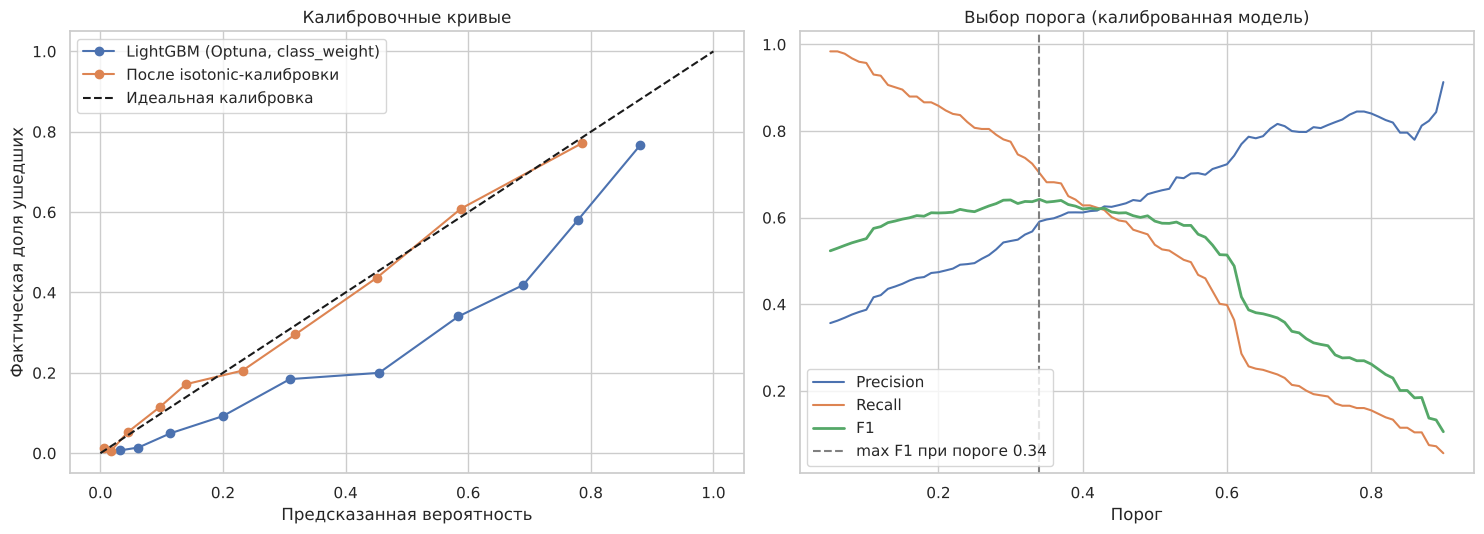

Оптимальный по F1 порог для калиброванной модели: 0.34, F1 = 0.6422


In [31]:
# ===== Бонус 3: калибровка вероятностей =====
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

calib_lgbm = CalibratedClassifierCV(clone(best_lgbm), method='isotonic',
                                    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
calib_lgbm = fit_timed(calib_lgbm, 'LGBM калибр.')
proba_cal = calib_lgbm.predict_proba(X_test)[:, 1]

print(f'Средняя предсказанная вероятность: до {y_proba_best.mean():.3f} | после {proba_cal.mean():.3f} | факт {y_test.mean():.3f}')
print(f'Brier score (меньше — лучше):      до {brier_score_loss(y_test, y_proba_best):.4f} | после {brier_score_loss(y_test, proba_cal):.4f}')
print(f'ROC-AUC:                           до {roc_auc_score(y_test, y_proba_best):.4f} | после {roc_auc_score(y_test, proba_cal):.4f}')

# Калибровочные кривые: идеальная модель лежит на диагонали
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for p, lbl in [(y_proba_best, 'LightGBM (Optuna, class_weight)'), (proba_cal, 'После isotonic-калибровки')]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, 'o-', label=lbl)
axes[0].plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
axes[0].set_xlabel('Предсказанная вероятность'); axes[0].set_ylabel('Фактическая доля ушедших')
axes[0].set_title('Калибровочные кривые'); axes[0].legend()

# Выбор порога: Precision / Recall / F1 в зависимости от порога (на калиброванных вероятностях)
thr = np.linspace(0.05, 0.9, 86)
prec = [precision_score(y_test, proba_cal >= t, zero_division=0) for t in thr]
rec = [recall_score(y_test, proba_cal >= t) for t in thr]
f1s = [f1_score(y_test, proba_cal >= t) for t in thr]
best_thr = thr[int(np.argmax(f1s))]
axes[1].plot(thr, prec, label='Precision'); axes[1].plot(thr, rec, label='Recall'); axes[1].plot(thr, f1s, label='F1', lw=2)
axes[1].axvline(best_thr, color='gray', ls='--', label=f'max F1 при пороге {best_thr:.2f}')
axes[1].set_xlabel('Порог'); axes[1].set_title('Выбор порога (калиброванная модель)'); axes[1].legend()
plt.tight_layout()
plt.show()
print(f'Оптимальный по F1 порог для калиброванной модели: {best_thr:.2f}, F1 = {max(f1s):.4f}')

In [32]:
# ===== Сводная таблица: базовые модели + Optuna + бонусы =====
all_results = pd.DataFrame(results + [res_opt, res_stack, res_smote]).set_index('Model')
all_results['Время, с'] = [train_times['Random Forest'], train_times['XGBoost'], train_times['LightGBM'],
                           train_times['CatBoost'], train_times['LightGBM (Optuna)'],
                           train_times['Stacking'], train_times['LGBM + SMOTE']]
display(all_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,"Время, с"
Model,,,,,,
Random Forest,0.7601,0.5346,0.7433,0.6219,0.8388,0.8040
XGBoost,0.7630,0.5417,0.6952,0.6089,0.8279,0.2014
LightGBM,0.7594,0.5332,0.7513,0.6238,0.8377,0.1949
CatBoost,0.7488,0.5187,0.7433,0.6110,0.8409,0.4814
LightGBM (Optuna),0.7424,0.5092,0.8102,0.6254,0.8495,0.1898
Stacking (4 модели),0.8041,0.6458,0.5802,0.6113,0.8478,9.0358
LightGBM + SMOTE,0.7601,0.5361,0.7139,0.6124,0.8355,0.4329


### 9.3 Выводы по бонусам
- **Stacking** — ROC-AUC 0.848, т.е. **не лучше** одной LightGBM после Optuna (0.850). Мета-модель отдала почти весь вес LightGBM (Optuna), немного — Random Forest, а CatBoost получил даже отрицательный вес: ошибки базовых моделей сильно коррелируют (все — деревья на одних и тех же признаках), и остальные модели почти ничего не добавляют к лучшей. При этом стекинг обучается в ~30 раз дольше — в продакшене не оправдано. Другой профиль метрик при пороге 0.5 (Precision выше, Recall ниже) объясняется тем, что мета-модель обучена без весов классов и даёт почти калиброванные вероятности.
- **SMOTE** — ROC-AUC 0.836 — **хуже**, чем та же модель с весами классов (0.850). На умеренном дисбалансе (1 : 2.8) веса классов дают тот же эффект проще и без синтетических объектов; SMOTE имеет смысл при сильном дисбалансе (1 : 20 и больше).
- **Калибровка** — практически полезнее всего. С `class_weight='balanced'` модель в среднем предсказывает вероятность ухода ≈ 0.41 при фактических 0.265, т.е. систематически завышает риск. Isotonic-калибровка выравнивает вероятности (средняя ≈ 0.266, Brier score 0.162 → 0.134) **без потери ROC-AUC**. Теперь «вероятность 0.6» действительно означает «из 10 таких клиентов уйдут ~6», и это можно использовать для расчёта ожидаемых потерь выручки и выбора порога под бюджет удержания (максимум F1 — при пороге ≈ 0.34 (F1 = 0.642)).

**Итоговая модель:** `best_lgbm` (LightGBM + Optuna) — лучший баланс качества, скорости и простоты. Она сохраняется как `models/best_model.pkl` и интерпретируется через SHAP ниже.

## Интерпретация через SHAP

Используем `TreeExplainer` — точный и быстрый алгоритм для деревьев. SHAP-значения LightGBM считаются в **логит-пространстве** (log-odds): положительное значение повышает шанс ухода, отрицательное — снижает. Для waterfall-графика подставляем исходные текстовые значения категорий, чтобы его можно было читать без таблицы кодов.

In [33]:
# ===== SHAP-значения для тестовой выборки =====
import shap

explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации старые версии SHAP возвращают список [класс 0, класс 1]
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values
# Базовое значение (средний логит) — тоже может быть списком/массивом
ev = explainer.expected_value
base_value = float(ev[1]) if np.ndim(ev) > 0 and len(np.atleast_1d(ev)) > 1 else float(np.atleast_1d(ev)[0])

print('Форма SHAP-матрицы:', shap_values_class1.shape)            # (клиенты, признаки)
print(f'Базовое значение (средний логит): {base_value:.4f} → вероятность {1/(1+np.exp(-base_value)):.3f}')
# Проверка аддитивности: базовое + сумма SHAP = логит модели
raw_logit = best_lgbm.predict_proba(X_test, raw_score=True)
print('Аддитивность выполняется:', np.allclose(base_value + shap_values_class1.sum(axis=1), raw_logit, atol=1e-4))

Форма SHAP-матрицы: (1409, 23)
Базовое значение (средний логит): -0.6155 → вероятность 0.351
Аддитивность выполняется: True


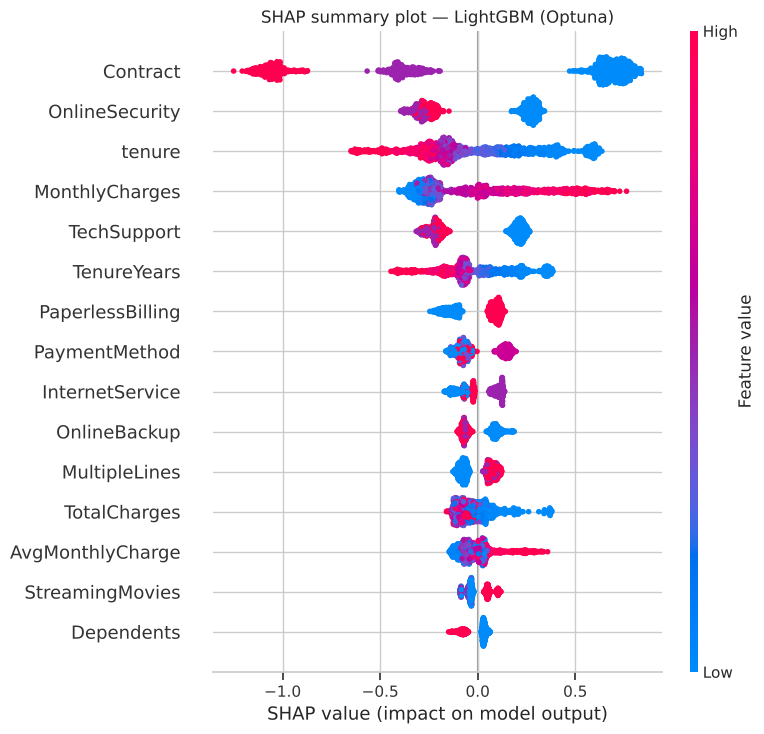

In [34]:
# ===== Summary plot (dot): важность + направление влияния =====
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', max_display=15, show=False)
plt.title('SHAP summary plot — LightGBM (Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=110, bbox_inches='tight')
plt.show()

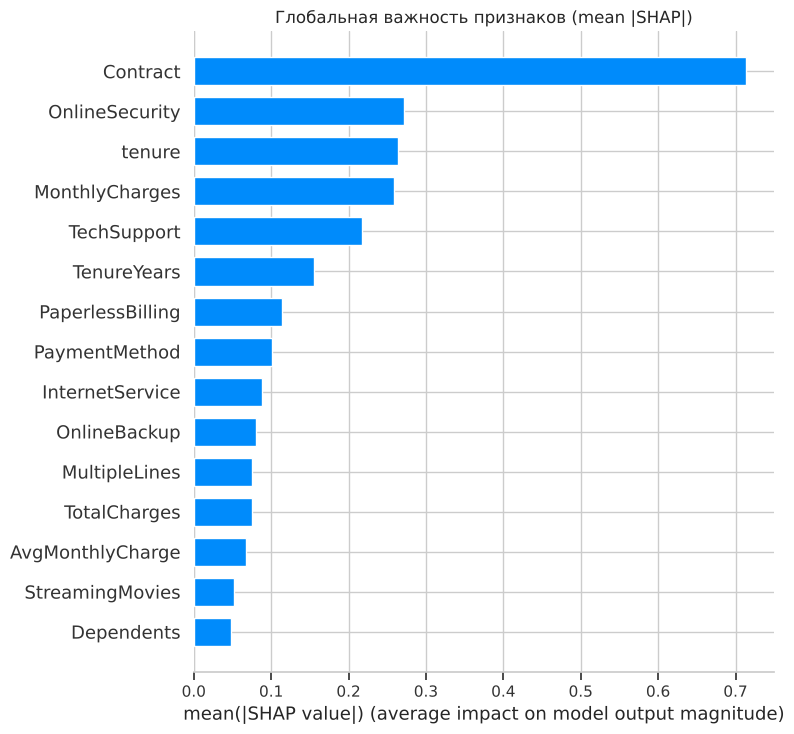

Топ-7 по mean|SHAP|:
Contract            0.7140
OnlineSecurity      0.2723
tenure              0.2633
MonthlyCharges      0.2587
TechSupport         0.2178
TenureYears         0.1552
PaperlessBilling    0.1137


In [35]:
# ===== Bar plot: глобальная важность = среднее |SHAP| =====
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', max_display=15, show=False)
plt.title('Глобальная важность признаков (mean |SHAP|)')
plt.tight_layout()
plt.show()

shap_imp = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=feature_cols).sort_values(ascending=False)
print('Топ-7 по mean|SHAP|:'); print(shap_imp.head(7).round(4).to_string())

Клиент #1090 (5178-LMXOP), вероятность ухода = 0.9452, факт: ушёл


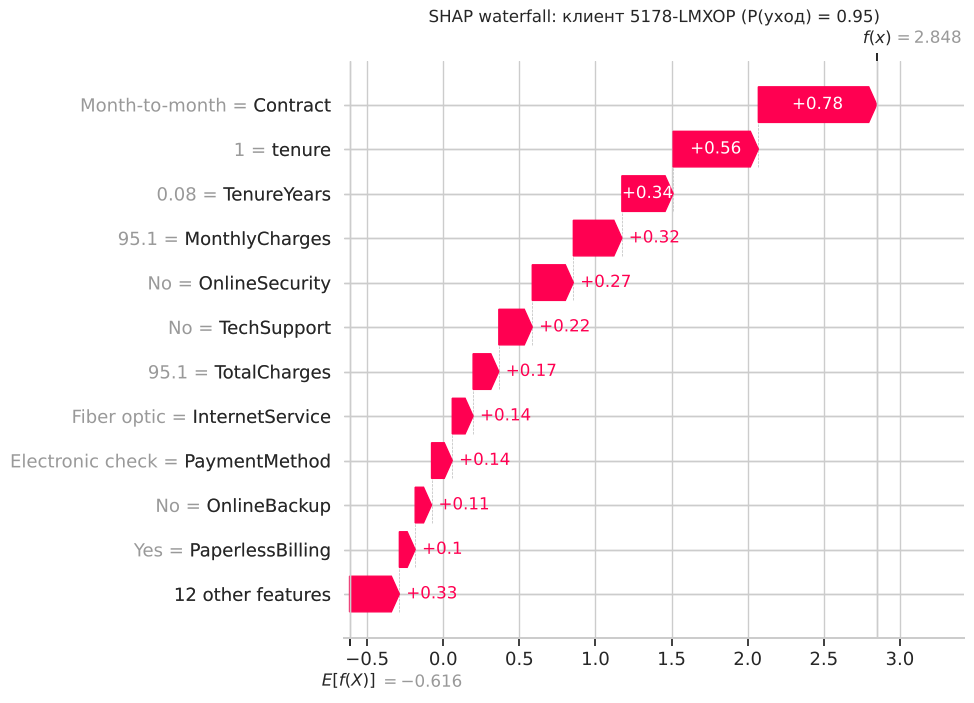

,значение,SHAP (логит)
Contract,Month-to-month,0.778
tenure,1,0.560
TenureYears,0.08,0.337
MonthlyCharges,95.1,0.319
OnlineSecurity,No,0.270
TechSupport,No,0.220
TotalCharges,95.1,0.169
InternetService,Fiber optic,0.137


In [36]:
# ===== Waterfall plot: объяснение для клиента с наибольшей вероятностью ухода =====
worst_idx = int(np.argmax(y_proba_best))                          # позиция в X_test
cust_id = df.loc[X_test.index[worst_idx], 'customerID']
print(f'Клиент #{worst_idx} ({cust_id}), вероятность ухода = {y_proba_best[worst_idx]:.4f}, '
      f'факт: {"ушёл" if y_test.iloc[worst_idx] == 1 else "остался"}')

# Человекочитаемые значения: берём исходную строку клиента из df_raw
raw_row = df_raw.loc[X_test.index[worst_idx]]
display_vals = [raw_row[c] if c in raw_row.index else round(X_test.iloc[worst_idx][c], 2) for c in feature_cols]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_value,
        data=X_test.iloc[worst_idx].values,
        display_data=np.array(display_vals, dtype=object),     # подписи: 'Month-to-month' вместо 0
        feature_names=X_test.columns.tolist()
    ),
    max_display=12, show=False
)
plt.title(f'SHAP waterfall: клиент {cust_id} (P(уход) = {y_proba_best[worst_idx]:.2f})')
plt.savefig('examples/shap_waterfall.png', dpi=110, bbox_inches='tight')
plt.show()

# Те же вклады таблицей
contrib = pd.DataFrame({'значение': display_vals, 'SHAP (логит)': shap_values_class1[worst_idx]},
                       index=feature_cols).sort_values('SHAP (логит)', key=abs, ascending=False)
display(contrib.head(8).round(3))

Самый важный признак по SHAP: Contract | коды: {0: 'Month-to-month', 1: 'One year', 2: 'Two year'}


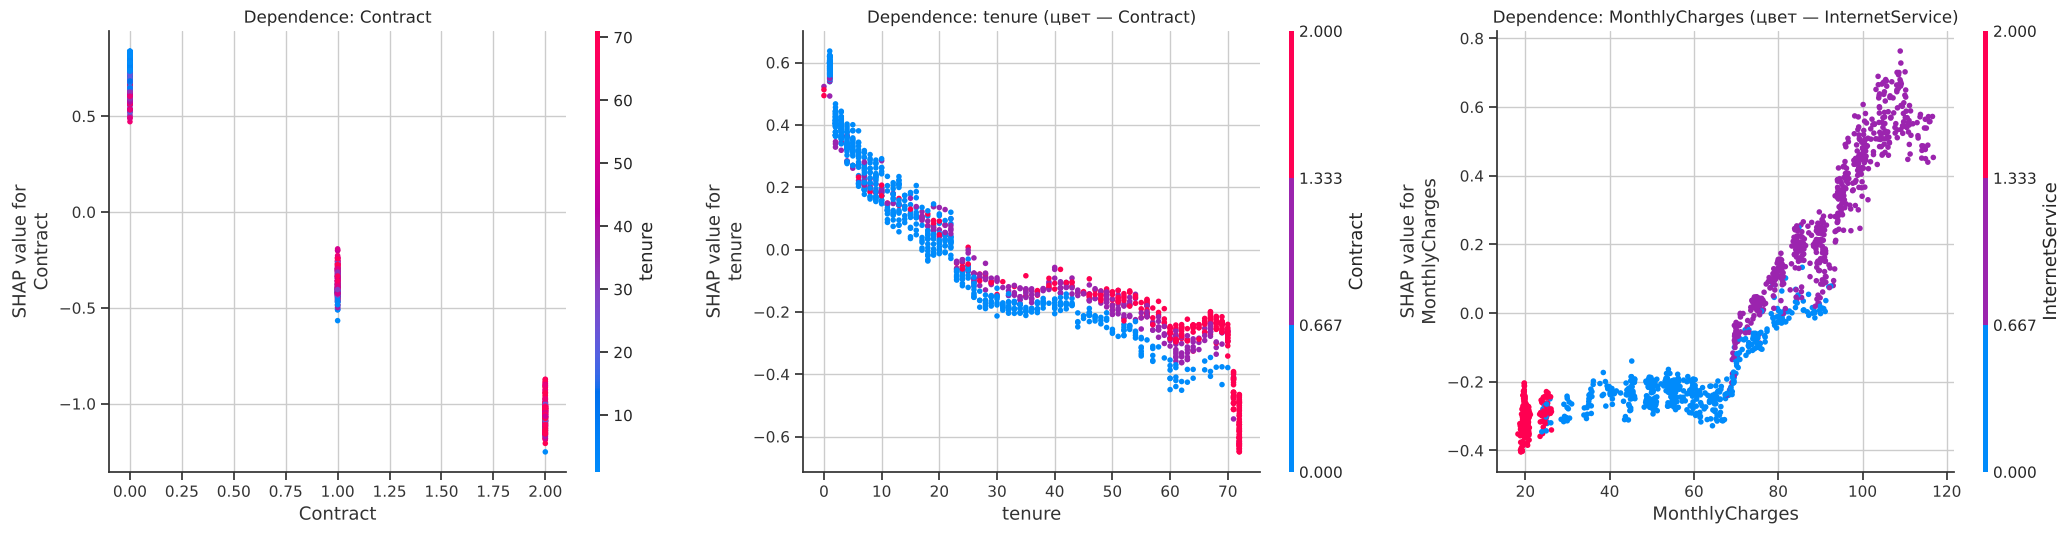

In [37]:
# ===== Dependence plots: главный признак + ключевые числовые =====
top_feature = shap_imp.index[0]                                   # самый важный по SHAP
print('Самый важный признак по SHAP:', top_feature,
      '| коды:', dict(enumerate(label_encoders[top_feature].classes_)) if top_feature in label_encoders else '')

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
shap.dependence_plot(top_feature, shap_values_class1, X_test, ax=axes[0], show=False)       # interaction подбирается автоматически
axes[0].set_title(f'Dependence: {top_feature}')
shap.dependence_plot('tenure', shap_values_class1, X_test, interaction_index='Contract', ax=axes[1], show=False)
axes[1].set_title('Dependence: tenure (цвет — Contract)')
shap.dependence_plot('MonthlyCharges', shap_values_class1, X_test, interaction_index='InternetService', ax=axes[2], show=False)
axes[2].set_title('Dependence: MonthlyCharges (цвет — InternetService)')
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=110, bbox_inches='tight')
plt.show()

## SHAP-интерпретация

*Коды категорий:* `Contract`: 0 — Month-to-month, 1 — One year, 2 — Two year; `InternetService`: 0 — DSL, 1 — Fiber optic, 2 — No; `OnlineSecurity`/`TechSupport`: 0 — No, 1 — No internet service, 2 — Yes; `PaymentMethod`: 2 — Electronic check.

**Что показывает Summary plot:**
- **Contract** — главный признак: месячный контракт (синие точки, код 0) сдвигает прогноз вправо — к уходу; годовые и двухлетние (красные) — сильно влево.
- **Короткий tenure** (синие точки) → выше вероятность ухода; длинный стаж (красные) стабильно снижает риск. Влияние нелинейное: основное падение риска — в первые 1–2 года.
- **Высокие MonthlyCharges** → увеличивают отток; **InternetService = Fiber optic** — тоже.
- **Наличие OnlineSecurity и TechSupport** (код 2 = Yes) → снижает отток; их отсутствие (код 0) — повышает.
- **PaymentMethod = Electronic check** и `PaperlessBilling = Yes` добавляют риск.
- `gender`, `PhoneService`, `StreamingTV` — около нуля: на прогноз почти не влияют.

**Waterfall plot для клиента с высоким риском** (5178-LMXOP, P(уход) = 0.945). Клиент уходит из-за:
1. **Contract = Month-to-month** (+0.78 к логиту) — самый большой вклад;
2. **tenure = 1 месяц** (+0.56, и ещё +0.34 через дублирующий TenureYears) — совсем новый клиент;
3. **MonthlyCharges = $95.1** (+0.32) — дорогой тариф;
4. **OnlineSecurity = No** (+0.27) и **TechSupport = No** (+0.22) — нет защитных услуг;
5. **InternetService = Fiber optic** (+0.14) и **PaymentMethod = Electronic check** (+0.14).

Ни один признак не тянет прогноз вниз — это «идеальный» портрет уходящего клиента, и он действительно ушёл. (Значения в логитах: от базового −0.62 до итогового +2.85, что соответствует вероятности 0.945.)

Каждый фактор добавляется к базовому логиту (средний клиент ≈ 0.35 вероятности при сбалансированных весах), и в сумме они дают итоговый прогноз — так модель можно «объяснить» менеджеру по удержанию: *почему* именно этот клиент в зоне риска и *что* ему предложить (годовой контракт, бесплатная техподдержка).

**Dependence plots:**
- **tenure:** SHAP резко падает в первые ~12 месяцев и затем выходит на плато; цвет показывает взаимодействие — при месячном контракте риск у новичков максимальный.
- **MonthlyCharges:** риск растёт примерно с \$65–70 — это порог, после которого у клиента, как правило, оптоволокно; при одинаковой плате оптоволокно (цвет) рискованнее DSL.
- SHAP подтверждает выводы Feature Importance (раздел 8) и EDA (раздел 5), но дополнительно даёт **направление** и **индивидуальное** объяснение для каждого клиента.

## Сохранение модели

Сохраняем в `models/`: 4 базовые модели + лучшую (`best_model.pkl` = LightGBM + Optuna), scaler, словарь LabelEncoder'ов, список признаков, параметры предобработки и метрики всех моделей.

In [38]:
# ===== Сохранение моделей и препроцессинга =====
os.makedirs('models', exist_ok=True)

# compress=3 — сжатие zlib: лес из 200 глубоких деревьев занимает ~12 МБ без сжатия и ~2 МБ со сжатием
joblib.dump(rf_model, 'models/rf_model.pkl', compress=3)       # Random Forest
joblib.dump(xgb_model, 'models/xgb_model.pkl', compress=3)               # XGBoost
joblib.dump(lgbm_model, 'models/lgbm_model.pkl', compress=3)             # LightGBM (baseline)
joblib.dump(cat_model, 'models/cat_model.pkl', compress=3)               # CatBoost
joblib.dump(best_lgbm, 'models/best_model.pkl', compress=3)              # ЛУЧШАЯ: LightGBM + Optuna
joblib.dump(scaler, 'models/scaler.pkl')                       # StandardScaler (для LogReg-ориентира)
joblib.dump(label_encoders, 'models/label_encoders.pkl')       # словарь {столбец: LabelEncoder}

# Список признаков в правильном порядке
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Параметры предобработки, нужные для новых «сырых» клиентов
preprocess_meta = {
    'total_charges_median': float(tc_median),                   # чем заполнять пустой TotalCharges
    'service_cols': service_cols,                               # для HasMultipleServices
    'categorical_cols': cat_features,                           # какие столбцы кодировать
    'new_client_threshold_months': 6,
    'calibrated_f1_threshold': float(best_thr),
}
with open('models/preprocess_meta.json', 'w', encoding='utf-8') as f:
    json.dump(preprocess_meta, f, ensure_ascii=False, indent=2)

In [39]:
# ===== Метрики всех моделей =====
def clean(r):
    """Метрики модели как словарь float без поля Model."""
    return {k: round(float(v), 4) for k, v in r.items() if k != 'Model'}

metrics = {
    'dataset': 'Telco Customer Churn (7043 x 21), test_size=0.2, stratify, random_state=42',
    'threshold': 0.5,
    'random_forest': {**clean(results[0]), 'train_time_sec': round(train_times['Random Forest'], 3),
                      'cv_roc_auc': round(float(cv_auc['Random Forest'].mean()), 4)},
    'xgboost':       {**clean(results[1]), 'train_time_sec': round(train_times['XGBoost'], 3),
                      'cv_roc_auc': round(float(cv_auc['XGBoost'].mean()), 4)},
    'lightgbm':      {**clean(results[2]), 'train_time_sec': round(train_times['LightGBM'], 3),
                      'cv_roc_auc': round(float(cv_auc['LightGBM'].mean()), 4)},
    'catboost':      {**clean(results[3]), 'train_time_sec': round(train_times['CatBoost'], 3),
                      'cv_roc_auc': round(float(cv_auc['CatBoost'].mean()), 4)},
    'lightgbm_optuna': {**clean(res_opt), 'train_time_sec': round(train_times['LightGBM (Optuna)'], 3)},
    'bonus_stacking': clean(res_stack),
    'bonus_lgbm_smote': clean(res_smote),
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': round(float(study.best_value), 4),          # лучший CV ROC-AUC в Optuna
    'best_test_roc_auc': round(float(res_opt['ROC-AUC']), 4),   # ROC-AUC лучшей модели на тесте
    'optuna_n_trials': len(study.trials),
    'best_params': study.best_params,
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print('✅ Все модели и метаданные сохранены')
for fn in sorted(os.listdir('models')):
    print(f'  models/{fn:<22} {os.path.getsize(os.path.join("models", fn)) / 1024:>8.1f} KB')

✅ Все модели и метаданные сохранены
  models/best_model.pkl            143.5 KB
  models/cat_model.pkl             103.8 KB
  models/feature_cols.json           0.4 KB
  models/label_encoders.pkl          4.0 KB
  models/lgbm_model.pkl            260.0 KB
  models/metrics.json                1.7 KB
  models/preprocess_meta.json        0.6 KB
  models/rf_model.pkl             2867.1 KB
  models/scaler.pkl                  1.7 KB
  models/xgb_model.pkl             232.0 KB


**Загрузка в репозиторий** (из корня `ml-course-botter`):
```bash
git add module-3-churn/
git commit -m "Module 3: ensemble models (RF, XGBoost, LightGBM, CatBoost), Optuna, SHAP"
git push origin main
```
Модели загружаются в ветку `main` (не в Releases), размер каждого файла — до нескольких МБ, Git LFS не требуется.

## Загрузка модели из репозитория

Загружаем модель, признаки и кодировщики по raw-ссылкам GitHub (путь включает папку `module-3-churn/`). Если сети нет (например, ноутбук запускают офлайн), функция берёт локальную копию — и честно пишет, откуда загружен файл.

In [40]:
# ===== Загрузка моделей из репозитория по raw-ссылке =====
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/uat0/ml-course-botter/main/module-3-churn"

def load_artifact(rel_path):
    """Скачивает файл из репозитория; если GitHub недоступен — читает локальную копию."""
    try:
        r = requests.get(f'{BASE_URL}/{rel_path}', timeout=20)
        r.raise_for_status()                                       # 404 → исключение
        print(f'🌐 {rel_path} — загружен из GitHub ({len(r.content) / 1024:.0f} KB)')
        return r.content
    except Exception as e:
        print(f'💾 {rel_path} — GitHub недоступен ({type(e).__name__}), читаю локальный файл')
        with open(rel_path, 'rb') as f:
            return f.read()

# Загрузка модели, признаков, кодировщиков и параметров предобработки
best_lgbm_loaded = joblib.load(BytesIO(load_artifact('models/best_model.pkl')))
feature_cols_loaded = json.loads(load_artifact('models/feature_cols.json'))
encoders_loaded = joblib.load(BytesIO(load_artifact('models/label_encoders.pkl')))
meta_loaded = json.loads(load_artifact('models/preprocess_meta.json'))

print('\n✅ Модель загружена из репозитория:', type(best_lgbm_loaded).__name__)
print(f'✅ Загружено {len(feature_cols_loaded)} признаков, {len(encoders_loaded)} кодировщиков')

🌐 models/best_model.pkl — загружен из GitHub (144 KB)


🌐 models/feature_cols.json — загружен из GitHub (0 KB)


🌐 models/label_encoders.pkl — загружен из GitHub (4 KB)


🌐 models/preprocess_meta.json — загружен из GitHub (1 KB)

✅ Модель загружена из репозитория: LGBMClassifier
✅ Загружено 23 признаков, 15 кодировщиков


In [41]:
# ===== Проверка: предсказания на 3 клиентах совпадают с исходной моделью =====
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])
proba_loaded = best_lgbm_loaded.predict_proba(X_test[feature_cols_loaded].iloc[:3])[:, 1]
proba_original = best_lgbm.predict_proba(X_test.iloc[:3])[:, 1]

print(f'Загруженная модель:  {y_pred_loaded}  вероятности {proba_loaded.round(4)}')
print(f'Исходная модель:     {y_pred_original}  вероятности {proba_original.round(4)}')
print(f'Истинные метки:      {y_test.iloc[:3].values}')
print(f'Совпадают: {np.array_equal(y_pred_loaded, y_pred_original) and np.allclose(proba_loaded, proba_original)}')

# И на всём тесте — метрика должна совпасть до последнего знака
auc_loaded = roc_auc_score(y_test, best_lgbm_loaded.predict_proba(X_test[feature_cols_loaded])[:, 1])
print(f'ROC-AUC загруженной модели на всём тесте: {auc_loaded:.4f} (исходная: {auc_opt:.4f})')

Загруженная модель:  [0 1 0]  вероятности [0.0743 0.8773 0.1968]
Исходная модель:     [0 1 0]  вероятности [0.0743 0.8773 0.1968]
Истинные метки:      [0 0 0]
Совпадают: True
ROC-AUC загруженной модели на всём тесте: 0.8495 (исходная: 0.8495)


In [42]:
# ===== Полный инференс для «сырых» клиентов (как они лежат в CSV) =====
def predict_churn(raw_clients, model=best_lgbm_loaded, encoders=encoders_loaded,
                  features=feature_cols_loaded, meta=meta_loaded):
    """Принимает DataFrame в исходном формате Telco и возвращает вероятность ухода."""
    d = raw_clients.copy()
    d['TotalCharges'] = pd.to_numeric(d['TotalCharges'], errors='coerce').fillna(meta['total_charges_median'])
    d = add_features(d)                                            # те же 4 новых признака
    for col, le in encoders.items():                               # те же коды категорий
        d[col] = le.transform(d[col])
    return pd.Series(model.predict_proba(d[features])[:, 1], index=d.index, name='P(уход)')

# Берём 3 клиента из тестовой выборки в «сыром» виде
sample_raw = df_raw.loc[X_test.index[:3]].drop(columns=['Churn'])
out = sample_raw[['customerID', 'tenure', 'Contract', 'InternetService', 'MonthlyCharges']].copy()
out['P(уход)'] = predict_churn(sample_raw).round(4).values
out['Истина'] = df_raw.loc[X_test.index[:3], 'Churn'].values
display(out)
print('Совпадает с вероятностями модели на подготовленных данных:',
      np.allclose(out['P(уход)'].values, proba_original.round(4)))

,customerID,tenure,Contract,InternetService,MonthlyCharges,P(уход),Истина
437,4376-KFVRS,72,Two year,Fiber optic,114.05,0.0743,No
2280,2754-SDJRD,8,Month-to-month,Fiber optic,100.15,0.8773,No
2235,9917-KWRBE,41,One year,DSL,78.35,0.1968,No


Совпадает с вероятностями модели на подготовленных данных: True


**Результат:** модель, признаки и кодировщики загружаются по raw-ссылкам из папки `module-3-churn/models/`, предсказания загруженной и исходной модели совпадают полностью (метки, вероятности и ROC-AUC на всём тесте). Функция `predict_churn()` показывает полный путь от «сырой» строки CSV до вероятности ухода — именно так модель использовалась бы в CRM.

## Выводы

### ✅ Что получилось
- Обучены и сравнены **4 ансамбля**: Random Forest, XGBoost, LightGBM, CatBoost. Все дают ROC-AUC **0.828–0.841** на тесте; лучший базовый — **CatBoost** (0.841). Ансамбли заметно сильнее одиночного дерева (AUC 0.743).
- **LightGBM + Optuna** (50 испытаний TPE): CV ROC-AUC 0.840 → **0.850**, тест **0.850** (Accuracy 0.742, Precision 0.509, Recall 0.810, F1 0.625). Это итоговая модель `best_model.pkl`.
- Модель находит ≈ **81%** реально уходящих клиентов при пороге 0.5.
- **Бонусы:** Stacking (AUC 0.848), SMOTE (AUC 0.836), калибровка вероятностей (Brier 0.162 → 0.134) и выбор порога.
- **Ключевые инсайты:** главные драйверы оттока — **месячный контракт, первые месяцы обслуживания, оптоволокно с высокой платой, отсутствие OnlineSecurity/TechSupport и оплата электронным чеком**. Все три метода интерпретации (EDA, Feature Importance, SHAP) согласуются.
- Модели и метаданные сохранены в `models/`, проверена загрузка по raw-ссылке из GitHub и полный инференс «сырых» клиентов.

### ⚠️ Трудности
- **Дисбаланс классов (73.5 / 26.5):** без весов классов модели находили бы менее половины уходящих. Веса решили проблему Recall, но исказили вероятности — пришлось отдельно калибровать.
- **Пропуски в TotalCharges** были «скрытыми»: столбец хранился строкой, а пропуски — пробелами, `isna()` их не видел. Обнаружились только после `pd.to_numeric(errors='coerce')`; все 11 — клиенты с `tenure = 0`.
- **Интерпретация категориальных признаков:** после LabelEncoder в графиках SHAP видны коды (0/1/2), а не названия. Для waterfall подставили исходные значения через `display_data`, для остальных графиков приведена таблица кодов. Кроме того, LabelEncoder задаёт произвольный порядок категорий — деревьям это не мешает, но разбиения по `PaymentMethod` получаются менее «чистыми».
- **Потолок качества:** все модели упираются в AUC ≈ 0.84–0.85 — различия между ними меньше разброса между фолдами CV, а простая логистическая регрессия (0.847) не уступает базовым ансамблям. Тюнинг дал скромный прирост (+0.012); дальше нужно не подбирать модели, а добавлять данные (история обращений в поддержку, качество связи, предложения конкурентов).
- **Совместимость версий:** pandas 3 хранит строки в новом типе `str`, поэтому отбор категориальных столбцов через `dtype == object` не работал — использован `select_dtypes(exclude='number')`.

### 🚀 Возможные улучшения
1. **Взаимодействия признаков:** `Contract × tenure`, `InternetService × MonthlyCharges`, «оптоволокно без защитных услуг», разница `MonthlyCharges − AvgMonthlyCharge` (недавнее повышение цены).
2. **Нативная работа с категориями:** передать категориальные столбцы в CatBoost (`cat_features`) и LightGBM (`categorical_feature`) вместо LabelEncoder — модели сами найдут оптимальные группировки категорий.
3. **Stacking с разнородными моделями:** добавить логистическую регрессию и kNN к деревьям — разнообразие базовых моделей важнее их числа (текущий стекинг из 4 деревьев почти ничего не дал).
4. **Оптимизация порога под бизнес-метрику:** вместо F1 — ожидаемая прибыль = (сохранённая выручка × вероятность успеха удержания) − стоимость контакта; порог выбирается под бюджет отдела удержания.
5. **Тюнинг всех 4 моделей в Optuna** (с прунингом `MedianPruner`) и подбор `scale_pos_weight` / весов классов как гиперпараметра.
6. **Probability calibration в продакшене** — сохранить калиброванную модель (`CalibratedClassifierCV`) как отдельный артефакт для расчёта ожидаемых потерь.
7. **Feature Store и MLOps:** версионирование признаков и моделей (DVC / MLflow), мониторинг дрейфа данных — например, если компания изменит тарифы на оптоволокно, модель нужно будет переобучить.
8. **Survival-анализ** (модель Кокса / Random Survival Forest): предсказывать не только «уйдёт ли», но и **когда** — это даёт окно для удержания.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD '16*, 785–794.
3. Ke, G., Meng, Q., Finley, T., et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *Proceedings of KDD '19*.
7. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189–1232.
8. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *JAIR*, 16, 321–357.
9. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. — гл. 10 «Boosting and Additive Trees», гл. 15 «Random Forests».
10. Kaggle. *Telco Customer Churn* (BlastChar / IBM Sample Data). https://www.kaggle.com/datasets/blastchar/telco-customer-churn
11. Документация: scikit-learn (ensemble, calibration) — https://scikit-learn.org/stable/modules/ensemble.html ; LightGBM — https://lightgbm.readthedocs.io/ ; Optuna — https://optuna.readthedocs.io/ ; SHAP — https://shap.readthedocs.io/
12. Материалы курса: «Модуль 3. Ансамблевые методы» (лекция и презентация).

In [43]:
# ===== requirements.txt с фактическими версиями библиотек =====
import importlib.metadata as im
pkgs = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'xgboost', 'lightgbm',
        'catboost', 'optuna', 'shap', 'imbalanced-learn', 'joblib', 'requests']
req = '\n'.join(f'{p}=={im.version(p)}' for p in pkgs)          # точные версии из окружения
with open('requirements.txt', 'w') as f:
    f.write(req + '\n')
print(req)

numpy==2.5.3
pandas==3.0.5
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==5.0.0
shap==0.54.1
imbalanced-learn==0.14.2
joblib==1.6.0
requests==2.34.2


## Приложение

### requirements.txt
Генерируется ячейкой выше из фактического окружения, файл — `module-3-churn/requirements.txt`.

### Структура модуля
```
module-3-churn/
├── README.md
├── notebook.ipynb
├── requirements.txt
├── data/          telco_churn.csv, churn_info.md
├── models/        best_model.pkl, rf/xgb/lgbm/cat_model.pkl, scaler.pkl, label_encoders.pkl,
│                  feature_cols.json, preprocess_meta.json, metrics.json
└── examples/      eda_plots.png, feature_importance.png, roc_curves.png, confusion_matrices.png,
                   optuna_history.png, shap_summary.png, shap_waterfall.png, shap_dependence.png
```

### Полный код ноутбука (формат Jupytext, ячейки разделены `# %%`)
```python
# %%
# ===== Импорт библиотек и общие настройки =====
import os, json, time, warnings                 # файлы, JSON, замер времени
warnings.filterwarnings('ignore')               # скрываем технические предупреждения библиотек

import numpy as np                              # численные вычисления
import pandas as pd                             # табличные данные
import matplotlib.pyplot as plt                 # графики
import seaborn as sns                           # статистическая визуализация
from IPython.display import display, Markdown   # красивый вывод таблиц в ноутбуке

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier               # градиентный бустинг №1
from lightgbm import LGBMClassifier             # градиентный бустинг №2
from catboost import CatBoostClassifier         # градиентный бустинг №3
import joblib                                   # сохранение моделей в .pkl

RANDOM_STATE = 42                               # фиксируем случайность для воспроизводимости
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')                # единый стиль графиков
plt.rcParams['figure.dpi'] = 100

# Папки для артефактов (все пути относительные — внутри module-3-churn/)
DATA_PATH = 'data/telco_churn.csv'
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)
print('✅ Библиотеки загружены | pandas', pd.__version__, '| numpy', np.__version__)

# %%
# ===== Загрузка датасета =====
df_raw = pd.read_csv(DATA_PATH)                 # исходный файл WA_Fn-UseC_-Telco-Customer-Churn.csv
df = df_raw.copy()                              # рабочая копия; df_raw оставляем «сырым» для раздела 12

print(df.shape)                                 # обязательный вывод размерности
print(df.head())                                # обязательный вывод первых строк

# %%
# ===== Структура датасета: типы признаков, пропуски, классы =====
features_raw = [c for c in df.columns if c not in ['customerID', 'Churn']]   # 19 исходных признаков
# Числовые по смыслу: tenure, MonthlyCharges, TotalCharges (TotalCharges пока строка — см. раздел 5)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in features_raw if c not in num_cols]                   # остальные 16 — категориальные
print(f'Всего примеров:           {len(df)}')
print(f'Признаков (без ID/цели):  {len(features_raw)}')
print(f'Числовых признаков:       {len(num_cols)}  {num_cols}')
print(f'Категориальных признаков: {len(cat_cols)} (включая SeniorCitizen 0/1)')

# Сводная таблица по столбцам: тип, число уникальных, доля «пустых» значений
tc_blank = (df['TotalCharges'].astype(str).str.strip() == '').sum()        # пустые строки ' ' в TotalCharges
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'пропуски, %': (df.isna().sum() / len(df) * 100).round(2),
    'пример': df.iloc[0],
})
summary.loc['TotalCharges', 'пропуски, %'] = round(tc_blank / len(df) * 100, 2)  # пробелы = скрытые пропуски
display(summary)

# Распределение классов целевой переменной
counts = df['Churn'].value_counts()
shares = df['Churn'].value_counts(normalize=True) * 100
print('\nРаспределение классов Churn:')
for cls in counts.index:
    print(f'  {cls:>3}: {counts[cls]:>5} ({shares[cls]:.1f}%)')
print(f'Скрытых пропусков в TotalCharges (пробел вместо числа): {tc_blank}')

# %%
# ===== Первичный осмотр =====
df.info()                                       # типы и ненулевые значения по столбцам

# %%
# Описательная статистика числовых и категориальных признаков
display(df.describe().round(2))                              # числовые: tenure, MonthlyCharges, SeniorCitizen
display(df.describe(exclude='number').T)                     # категориальные: число уникальных, мода, частота

# %%
# ===== Анализ пропусков =====
# Явных NaN в файле нет, но TotalCharges хранится строкой, и у части клиентов там пробел ' '
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   # ' ' → NaN
missing = df.isna().sum()                                                   # число пропусков по столбцам
print('Пропуски после приведения TotalCharges к числу:')
print(missing[missing > 0])

# Кто эти клиенты? Смотрим их tenure и Churn
nan_rows = df[df['TotalCharges'].isna()]
print('\ntenure у клиентов с пропуском:', nan_rows['tenure'].unique())
print('Churn у клиентов с пропуском:  ', nan_rows['Churn'].value_counts().to_dict())

# Визуализация пропусков: доля по каждому столбцу
fig, ax = plt.subplots(figsize=(12, 3.5))
(df.isna().mean() * 100).plot(kind='bar', color=['tab:red' if v > 0 else 'tab:gray' for v in df.isna().mean()], ax=ax)
ax.set_ylabel('% пропусков')
ax.set_title('Доля пропусков по столбцам (после pd.to_numeric для TotalCharges)')
plt.tight_layout()
plt.show()

# %%
# ===== Анализ целевой переменной =====
print(df['Churn'].value_counts())                            # абсолютные значения
print((df['Churn'].value_counts(normalize=True) * 100).round(1))  # доли в %
# Кодируем целевую в бинарный вид: Yes → 1, No → 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
print('\nДоля ушедших (Churn=1):', round(df['Churn'].mean(), 4))

# %%
# ===== EDA: сетка из 6 графиков (сохраняется в examples/eda_plots.png) =====
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
churn_lbl = {0: 'Остался', 1: 'Ушёл'}                        # подписи классов
pal = {0: '#4C72B0', 1: '#DD5555'}                           # единые цвета классов

# 1) Countplot целевой
ax = axes[0, 0]
sns.countplot(data=df, x='Churn', hue='Churn', palette=pal, legend=False, ax=ax)
for p in ax.patches:                                          # подписываем доли над столбцами
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.0f}\n({p.get_height()/len(df):.1%})',
                    (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Остался (0)', 'Ушёл (1)'])
ax.set_ylim(0, 6200)
ax.set_title('1. Распределение целевой Churn')

# 2) Гистограмма tenure по классам
ax = axes[0, 1]
sns.histplot(data=df, x='tenure', hue='Churn', palette=pal, bins=36, kde=True, alpha=0.5, ax=ax)
ax.set_title('2. Стаж клиента (tenure) по классам')
ax.set_xlabel('tenure, месяцев'); ax.legend(['Ушёл', 'Остался'])

# 3) Boxplot ежемесячной платы
ax = axes[0, 2]
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette=pal, legend=False, ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Остался', 'Ушёл'])
ax.set_title('3. MonthlyCharges по классам')

# 4) Корреляционная матрица числовых признаков (+ целевая)
ax = axes[1, 0]
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('4. Корреляции числовых признаков')

# 5) Доля ушедших по типу контракта
ax = axes[1, 1]
rate_contract = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
sns.barplot(x=rate_contract.index, y=rate_contract.values * 100, hue=rate_contract.index,
            palette='Reds_r', legend=False, ax=ax)
for i, v in enumerate(rate_contract.values):                  # подписи процентов
    ax.text(i, v * 100 + 1, f'{v:.1%}', ha='center')
ax.set_ylabel('Доля ушедших, %'); ax.set_xlabel('')
ax.set_title('5. Отток по типу контракта')

# 6) Доля ушедших по типу интернета
ax = axes[1, 2]
rate_inet = df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False)
sns.barplot(x=rate_inet.index, y=rate_inet.values * 100, hue=rate_inet.index,
            palette='Oranges_r', legend=False, ax=ax)
for i, v in enumerate(rate_inet.values):
    ax.text(i, v * 100 + 1, f'{v:.1%}', ha='center')
ax.set_ylabel('Доля ушедших, %'); ax.set_xlabel('')
ax.set_title('6. Отток по типу интернета')

plt.suptitle('EDA: Telco Customer Churn', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')   # сохраняем для README
plt.show()

# %%
# ===== Дополнительные графики: способ оплаты, доп. услуги, пенсионеры =====
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 7) Отток по способу оплаты
rate_pay = df.groupby('PaymentMethod')['Churn'].mean().sort_values(ascending=False) * 100
rate_pay.plot(kind='barh', color='indianred', ax=axes[0])
axes[0].invert_yaxis(); axes[0].set_xlabel('Доля ушедших, %')
axes[0].set_title('7. Отток по способу оплаты')

# 8) Отток в зависимости от наличия защитных услуг (только у клиентов с интернетом)
inet = df[df['InternetService'] != 'No']                       # у кого нет интернета — услуги недоступны
svc_rates = pd.DataFrame({s: inet.groupby(s)['Churn'].mean() * 100
                          for s in ['OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection']}).T
svc_rates[['No', 'Yes']].plot(kind='bar', color=['indianred', 'seagreen'], ax=axes[1], rot=0)
axes[1].set_ylabel('Доля ушедших, %'); axes[1].legend(title='Услуга подключена')
axes[1].set_title('8. Отток vs доп. услуги (клиенты с интернетом)')

# 9) Отток по группам стажа
bins = [-1, 6, 12, 24, 48, 72]                                  # границы групп tenure
labels = ['0–6', '7–12', '13–24', '25–48', '49–72']
rate_ten = df.groupby(pd.cut(df['tenure'], bins=bins, labels=labels), observed=True)['Churn'].mean() * 100
rate_ten.plot(kind='bar', color='steelblue', ax=axes[2], rot=0)
for i, v in enumerate(rate_ten.values):
    axes[2].text(i, v + 1, f'{v:.0f}%', ha='center')
axes[2].set_xlabel('tenure, месяцев'); axes[2].set_ylabel('Доля ушедших, %')
axes[2].set_title('9. Отток по стажу клиента')

plt.tight_layout()
plt.show()

# %%
# ===== Обработка пропусков =====
# 11 клиентов с пустым TotalCharges имеют tenure = 0: это новые клиенты, которым ещё не выставлен первый счёт.
# Стратегия по заданию — медиана. Пропусков всего 0.16%, поэтому выбор стратегии почти не влияет на модель;
# медиана устойчива к выбросам (распределение TotalCharges сильно скошено вправо, среднее > медианы).
tc_median = df['TotalCharges'].median()                       # медиана по всем клиентам
df['TotalCharges'] = df['TotalCharges'].fillna(tc_median)     # заполняем пропуски
print(f'Медиана TotalCharges = {tc_median:.2f}')
print('Пропусков осталось:', int(df.isna().sum().sum()))

# %%
# ===== Feature Engineering =====
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    """Создаёт 4 новых признака. Применяется одинаково к обучающим и к новым данным."""
    data = data.copy()
    data['TenureYears'] = data['tenure'] / 12                                   # стаж в годах
    data['AvgMonthlyCharge'] = data['TotalCharges'] / (data['tenure'] + 1)      # средний фактический платёж (+1 от деления на 0)
    data['IsNewClient'] = (data['tenure'] <= 6).astype(int)                     # новичок: первые полгода — зона риска
    # Счётчик подключённых услуг: телефонные/доп. услуги со значением 'Yes' + сам интернет
    data['HasMultipleServices'] = ((data[service_cols] == 'Yes').sum(axis=1)
                                   + (data['InternetService'] != 'No').astype(int))
    return data

df = add_features(df)                                         # применяем к датасету
new_feats = ['TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']
display(df[new_feats + ['Churn']].describe().round(2))

# Как новые признаки связаны с оттоком
print('Доля ушедших среди новичков (IsNewClient=1):', round(df.loc[df.IsNewClient == 1, 'Churn'].mean(), 3))
print('Доля ушедших среди остальных (IsNewClient=0):', round(df.loc[df.IsNewClient == 0, 'Churn'].mean(), 3))
print('\nДоля ушедших по числу услуг:')
print(df.groupby('HasMultipleServices')['Churn'].agg(['mean', 'size']).round(3).T)

# %%
# ===== Кодирование категориальных признаков =====
# Churn уже переведён в 0/1. Все строковые признаки кодируем LabelEncoder'ом:
# деревьям не нужен One-Hot — они сами находят нужные пороги по коду категории.
cat_features = [c for c in df.select_dtypes(exclude='number').columns if c != 'customerID']
label_encoders = {}                                           # словарь кодировщиков (сохраним в .pkl)
for col in cat_features:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])                       # строка → целое число
    label_encoders[col] = le                                  # запоминаем для инференса
    print(f'{col:<18} → {dict(zip(le.classes_, le.transform(le.classes_)))}')
print(f'\nЗакодировано признаков: {len(cat_features)}')

# %%
# ===== Формирование X, y и разбиение train/test =====
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]   # 19 исходных + 4 новых
X = df[feature_cols]
y = df['Churn']

# stratify=y — сохраняем долю ушедших (26.5%) и в train, и в test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Признаков: {len(feature_cols)}')
print(f'Train: {X_train.shape}, доля Churn=1: {y_train.mean():.3f}')
print(f'Test:  {X_test.shape},  доля Churn=1: {y_test.mean():.3f}')

# Масштабирование нужно только линейной модели-ориентиру (деревьям — нет).
# Scaler обучаем ТОЛЬКО на train, чтобы не было утечки информации из test.
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

# %%
# ===== Функция для обучения с замером времени =====
train_times = {}                                              # сюда пишем время обучения каждой модели

def fit_timed(model, name, Xtr=X_train, ytr=y_train):
    """Обучает модель и печатает время обучения."""
    start = time.time()
    model.fit(Xtr, ytr)
    train_times[name] = time.time() - start                   # секунды
    print(f'⏱️ Время обучения {name:<15}: {train_times[name]:.3f} сек')
    return model

# %%
# ===== 1. Random Forest (bagging) =====
rf_model = RandomForestClassifier(
    n_estimators=200,             # 200 деревьев
    max_depth=10,                 # ограничиваем глубину, чтобы деревья не запоминали шум
    class_weight='balanced',      # веса классов обратно пропорциональны их частоте
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model = fit_timed(rf_model, 'Random Forest')

# ===== 2. XGBoost (boosting) =====
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,      # стохастичность: 90% строк и признаков на дерево
    scale_pos_weight=3,                       # компенсация дисбаланса (≈ 5174/1869)
    random_state=RANDOM_STATE, eval_metric='logloss'
)
xgb_model = fit_timed(xgb_model, 'XGBoost')

# ===== 3. LightGBM (boosting) =====
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=RANDOM_STATE, verbose=-1    # verbose=-1 — без служебного вывода
)
lgbm_model = fit_timed(lgbm_model, 'LightGBM')

# ===== 4. CatBoost (boosting) =====
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced',            # аналог class_weight='balanced'
    random_state=RANDOM_STATE, verbose=0
)
cat_model = fit_timed(cat_model, 'CatBoost')

# %%
# ===== Модели-ориентиры (одиночные) =====
# Одиночное глубокое дерево: такое же, как в лесу, но одно
tree_model = fit_timed(DecisionTreeClassifier(max_depth=10, class_weight='balanced',
                                              random_state=RANDOM_STATE), 'Decision Tree')
# Логистическая регрессия на масштабированных признаках
lr_model = fit_timed(LogisticRegression(max_iter=2000, class_weight='balanced'),
                     'LogReg', Xtr=X_train_sc)

# %%
# ===== Сводная таблица моделей (время подставляется автоматически) =====
models_info = [
    ('Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced'),
    ('XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3'),
    ('LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05'),
    ('CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced'),
    ('Decision Tree', 'Одиночная (ориентир)', 'max_depth=10'),
    ('LogReg',        'Одиночная (ориентир)', 'StandardScaler + class_weight=balanced'),
]
table = '| Модель | Тип | Параметры | Время обучения |\n|---|---|---|---|\n'
table += '\n'.join(f'| {n} | {t} | {p} | {train_times[n]:.3f} сек |' for n, t, p in models_info)
display(Markdown(table))

# %%
# ===== Функция расчёта метрик =====
def evaluate_model(model, X_test, y_test, name):
    """Возвращает словарь метрик для модели на тестовой выборке."""
    y_pred = model.predict(X_test)                            # метки при пороге 0.5
    y_proba = model.predict_proba(X_test)[:, 1]               # вероятность класса «ушёл»
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba),
    }

# 4 обязательные модели
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost'),
]
# Ориентиры (одиночные модели) — отдельным списком, чтобы results остался из 4 ансамблей
baselines = [
    evaluate_model(tree_model, X_test, y_test, 'Decision Tree'),
    evaluate_model(lr_model, X_test_sc, y_test, 'LogReg'),
]
results_df = pd.DataFrame(results + baselines)
results_df['Время, с'] = results_df['Model'].map(train_times)
print(results_df.round(4).to_string(index=False))

# %%
# ===== Устойчивость: ROC-AUC на 5-fold CV (только train) =====
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = {}
for model, name in [(rf_model, 'Random Forest'), (xgb_model, 'XGBoost'),
                    (lgbm_model, 'LightGBM'), (cat_model, 'CatBoost'), (tree_model, 'Decision Tree')]:
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='roc_auc')   # 5 обучений
    cv_auc[name] = scores
    print(f'{name:<14} CV ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}')
results_df['CV ROC-AUC'] = results_df['Model'].map(lambda n: cv_auc[n].mean() if n in cv_auc else np.nan)

# %%
# ===== Визуальное сравнение метрик =====
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
plot_df = results_df.melt(id_vars='Model', value_vars=metric_names, var_name='Метрика', value_name='Значение')
plt.figure(figsize=(14, 5))
sns.barplot(data=plot_df, x='Метрика', y='Значение', hue='Model', palette='tab10')
plt.ylim(0.4, 0.9)
plt.title('Сравнение моделей на тестовой выборке (порог 0.5)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# %%
# ===== Матрицы ошибок 4 ансамблей; лучшая модель — по ROC-AUC =====
ens_models = {'Random Forest': rf_model, 'XGBoost': xgb_model, 'LightGBM': lgbm_model, 'CatBoost': cat_model}
best_name = max(results, key=lambda r: r['ROC-AUC'])['Model']    # лучшая по ROC-AUC
print('Лучшая модель по ROC-AUC на тесте:', best_name)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, ens_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))         # [[TN, FP], [FN, TP]]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
    ax.set_xlabel('Предсказано'); ax.set_ylabel('Истинно')
    ax.set_title(name + ('  ★ лучшая' if name == best_name else ''))
plt.suptitle('Матрицы ошибок (тест, порог 0.5)', y=1.03)
plt.tight_layout()
plt.savefig('examples/confusion_matrices.png', dpi=110, bbox_inches='tight')
plt.show()

# Подробный отчёт по лучшей модели
y_pred_best_base = ens_models[best_name].predict(X_test)
print(classification_report(y_test, y_pred_best_base, target_names=['Остался', 'Ушёл'], digits=3))

# %%
# ===== ROC-кривые всех 4 моделей на одном графике =====
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'Random Forest'), (xgb_model, 'XGBoost'),
                    (lgbm_model, 'LightGBM'), (cat_model, 'CatBoost')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)                   # точки кривой при всех порогах
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)
# Для сравнения — одиночное дерево пунктиром
fpr, tpr, _ = roc_curve(y_test, tree_model.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, ':', color='gray', label=f'Decision Tree (AUC = {roc_auc_score(y_test, tree_model.predict_proba(X_test)[:, 1]):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=110, bbox_inches='tight')
plt.show()

# %%
# ===== Итоговая таблица в Markdown (числа подставляются из results_df) =====
t = '| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | CV ROC-AUC | Время, с |\n|---|---|---|---|---|---|---|---|\n'
for _, r in results_df.iterrows():
    t += (f"| {r['Model']} | {r['Accuracy']:.3f} | {r['Precision']:.3f} | {r['Recall']:.3f} | "
          f"{r['F1']:.3f} | {r['ROC-AUC']:.3f} | {r['CV ROC-AUC']:.3f} | {r['Время, с']:.2f} |\n")
display(Markdown(t))

# %%
# ===== Feature Importance: RF (Gini) и LightGBM (split и gain) =====
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)
importances = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
           .sort_values('Importance', ascending=False)                       # split-важность LightGBM
gain = lgbm_model.booster_.feature_importance(importance_type='gain')        # gain-важность LightGBM
imp_gain = pd.DataFrame({'Feature': feature_cols, 'Importance': gain / gain.sum()}) \
           .sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
sns.barplot(data=imp_rf.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('ТОП-15 признаков: Random Forest (Gini)')
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('ТОП-15 признаков: LightGBM (split — число разбиений)')
sns.barplot(data=imp_gain.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=axes[2])
axes[2].set_title('ТОП-15 признаков: LightGBM (gain — прирост качества)')
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=110, bbox_inches='tight')
plt.show()

print('Топ-5 RF:          ', imp_rf['Feature'].head(5).tolist())
print('Топ-5 LGBM (split):', importances['Feature'].head(5).tolist())
print('Топ-5 LGBM (gain): ', imp_gain['Feature'].head(5).tolist())

# %%
# ===== Бизнес-цифры: доля оттока по ключевым сегментам (исходные категории) =====
seg = df_raw.copy()
seg['Churn'] = (seg['Churn'] == 'Yes').astype(int)
seg['tenure_group'] = pd.cut(seg['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                             labels=['0–6 мес', '7–12 мес', '1–2 года', '2–4 года', '4–6 лет'])
for col in ['Contract', 'tenure_group', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport']:
    t = seg.groupby(col, observed=True)['Churn'].agg(['mean', 'size']).rename(columns={'mean': 'доля оттока', 'size': 'клиентов'})
    t['доля оттока'] = (t['доля оттока'] * 100).round(1)
    print(f'--- {col} ---'); print(t.sort_values('доля оттока', ascending=False).to_string()); print()

# Во сколько раз месячный контракт рискованнее годового
r = seg.groupby('Contract')['Churn'].mean()
print(f"Месячный / годовой контракт: в {r['Month-to-month'] / r['One year']:.1f} раза больше оттока")
print(f"Месячный / двухлетний:       в {r['Month-to-month'] / r['Two year']:.1f} раз больше оттока")

# %%
# ===== Optuna: байесовская оптимизация LightGBM =====
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)          # без лога по каждому испытанию

def objective(trial):
    """Целевая функция: средний ROC-AUC на 5-fold CV для набора гиперпараметров."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),    # лог-шкала
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),            # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),          # L2
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1)
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        scoring='roc_auc'
    )
    return cv_scores.mean()

N_TRIALS = 50
start = time.time()
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))   # воспроизводимый TPE
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
optuna_time = time.time() - start

print(f'Испытаний: {len(study.trials)}, время: {optuna_time:.1f} сек')
print(f'Best CV ROC-AUC: {study.best_value:.4f} (испытание №{study.best_trial.number})')
print('Лучшие параметры:')
for key, value in study.best_params.items():
    print(f'  {key}: {round(value, 5) if isinstance(value, float) else value}')

# %%
# ===== История оптимизации и важность гиперпараметров =====
trials_df = study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(trials_df['number'], trials_df['value'], 'o', alpha=0.5, label='Испытание')
axes[0].plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')
lgbm_base_cv = cv_auc['LightGBM'].mean()
axes[0].axhline(lgbm_base_cv, color='gray', ls='--', label=f'Baseline LightGBM CV = {lgbm_base_cv:.4f}')
axes[0].set_xlabel('Номер испытания'); axes[0].set_ylabel('CV ROC-AUC')
axes[0].set_title('История оптимизации Optuna (TPE)'); axes[0].legend()

# Важность гиперпараметров (fANOVA): какие параметры сильнее всего влияют на ROC-AUC
param_imp = optuna.importance.get_param_importances(study)
pd.Series(param_imp).sort_values().plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Важность гиперпараметров (Optuna, fANOVA)')
plt.tight_layout()
plt.savefig('examples/optuna_history.png', dpi=110, bbox_inches='tight')
plt.show()

# %%
# ===== Обучаем лучшую модель и сравниваем с baseline на тесте =====
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1,
                           class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)
best_lgbm = fit_timed(best_lgbm, 'LightGBM (Optuna)')

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
auc_opt = roc_auc_score(y_test, y_proba_best)
print(f'ROC-AUC baseline (тест): {auc_base:.4f}')
print(f'ROC-AUC Optuna   (тест): {auc_opt:.4f}')
print(f'Прирост: {auc_opt - auc_base:+.4f} ({(auc_opt / auc_base - 1) * 100:+.2f}%)')
print(f'CV ROC-AUC: baseline {lgbm_base_cv:.4f} → Optuna {study.best_value:.4f}')

# Полная строка метрик для таблицы сравнения
res_opt = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')
cmp = pd.DataFrame([r for r in results if r['Model'] == 'LightGBM'] + [res_opt]).set_index('Model')
display(cmp.round(4))

# %%
# ===== Бонус 1: Stacking из 4 ансамблей =====
from sklearn.ensemble import StackingClassifier
from sklearn.base import clone

stack_model = StackingClassifier(
    estimators=[('rf', clone(rf_model)), ('xgb', clone(xgb_model)),
                ('lgbm', clone(best_lgbm)), ('cat', clone(cat_model))],   # базовые модели (необученные копии)
    final_estimator=LogisticRegression(max_iter=1000),                     # мета-модель
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),        # out-of-fold предсказания
    stack_method='predict_proba', n_jobs=1
)
stack_model = fit_timed(stack_model, 'Stacking')
res_stack = evaluate_model(stack_model, X_test, y_test, 'Stacking (4 модели)')
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_stack.items()})
print('Веса мета-модели (rf, xgb, lgbm, cat):', stack_model.final_estimator_.coef_.round(2))

# %%
# ===== Бонус 2: SMOTE вместо весов классов =====
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)    # балансируем ТОЛЬКО train
print('До SMOTE:   ', y_train.value_counts().to_dict())
print('После SMOTE:', y_train_sm.value_counts().to_dict())

# Та же лучшая конфигурация LightGBM, но без class_weight — баланс даёт SMOTE
params_no_w = {**study.best_params, 'subsample_freq': 1}
lgbm_smote = LGBMClassifier(**params_no_w, random_state=RANDOM_STATE, verbose=-1)
lgbm_smote = fit_timed(lgbm_smote, 'LGBM + SMOTE', Xtr=X_train_sm, ytr=y_train_sm)
res_smote = evaluate_model(lgbm_smote, X_test, y_test, 'LightGBM + SMOTE')
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_smote.items()})

# %%
# ===== Бонус 3: калибровка вероятностей =====
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

calib_lgbm = CalibratedClassifierCV(clone(best_lgbm), method='isotonic',
                                    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
calib_lgbm = fit_timed(calib_lgbm, 'LGBM калибр.')
proba_cal = calib_lgbm.predict_proba(X_test)[:, 1]

print(f'Средняя предсказанная вероятность: до {y_proba_best.mean():.3f} | после {proba_cal.mean():.3f} | факт {y_test.mean():.3f}')
print(f'Brier score (меньше — лучше):      до {brier_score_loss(y_test, y_proba_best):.4f} | после {brier_score_loss(y_test, proba_cal):.4f}')
print(f'ROC-AUC:                           до {roc_auc_score(y_test, y_proba_best):.4f} | после {roc_auc_score(y_test, proba_cal):.4f}')

# Калибровочные кривые: идеальная модель лежит на диагонали
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for p, lbl in [(y_proba_best, 'LightGBM (Optuna, class_weight)'), (proba_cal, 'После isotonic-калибровки')]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, 'o-', label=lbl)
axes[0].plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
axes[0].set_xlabel('Предсказанная вероятность'); axes[0].set_ylabel('Фактическая доля ушедших')
axes[0].set_title('Калибровочные кривые'); axes[0].legend()

# Выбор порога: Precision / Recall / F1 в зависимости от порога (на калиброванных вероятностях)
thr = np.linspace(0.05, 0.9, 86)
prec = [precision_score(y_test, proba_cal >= t, zero_division=0) for t in thr]
rec = [recall_score(y_test, proba_cal >= t) for t in thr]
f1s = [f1_score(y_test, proba_cal >= t) for t in thr]
best_thr = thr[int(np.argmax(f1s))]
axes[1].plot(thr, prec, label='Precision'); axes[1].plot(thr, rec, label='Recall'); axes[1].plot(thr, f1s, label='F1', lw=2)
axes[1].axvline(best_thr, color='gray', ls='--', label=f'max F1 при пороге {best_thr:.2f}')
axes[1].set_xlabel('Порог'); axes[1].set_title('Выбор порога (калиброванная модель)'); axes[1].legend()
plt.tight_layout()
plt.show()
print(f'Оптимальный по F1 порог для калиброванной модели: {best_thr:.2f}, F1 = {max(f1s):.4f}')

# %%
# ===== Сводная таблица: базовые модели + Optuna + бонусы =====
all_results = pd.DataFrame(results + [res_opt, res_stack, res_smote]).set_index('Model')
all_results['Время, с'] = [train_times['Random Forest'], train_times['XGBoost'], train_times['LightGBM'],
                           train_times['CatBoost'], train_times['LightGBM (Optuna)'],
                           train_times['Stacking'], train_times['LGBM + SMOTE']]
display(all_results.round(4))

# %%
# ===== SHAP-значения для тестовой выборки =====
import shap

explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации старые версии SHAP возвращают список [класс 0, класс 1]
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values
# Базовое значение (средний логит) — тоже может быть списком/массивом
ev = explainer.expected_value
base_value = float(ev[1]) if np.ndim(ev) > 0 and len(np.atleast_1d(ev)) > 1 else float(np.atleast_1d(ev)[0])

print('Форма SHAP-матрицы:', shap_values_class1.shape)            # (клиенты, признаки)
print(f'Базовое значение (средний логит): {base_value:.4f} → вероятность {1/(1+np.exp(-base_value)):.3f}')
# Проверка аддитивности: базовое + сумма SHAP = логит модели
raw_logit = best_lgbm.predict_proba(X_test, raw_score=True)
print('Аддитивность выполняется:', np.allclose(base_value + shap_values_class1.sum(axis=1), raw_logit, atol=1e-4))

# %%
# ===== Summary plot (dot): важность + направление влияния =====
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', max_display=15, show=False)
plt.title('SHAP summary plot — LightGBM (Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=110, bbox_inches='tight')
plt.show()

# %%
# ===== Bar plot: глобальная важность = среднее |SHAP| =====
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', max_display=15, show=False)
plt.title('Глобальная важность признаков (mean |SHAP|)')
plt.tight_layout()
plt.show()

shap_imp = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=feature_cols).sort_values(ascending=False)
print('Топ-7 по mean|SHAP|:'); print(shap_imp.head(7).round(4).to_string())

# %%
# ===== Waterfall plot: объяснение для клиента с наибольшей вероятностью ухода =====
worst_idx = int(np.argmax(y_proba_best))                          # позиция в X_test
cust_id = df.loc[X_test.index[worst_idx], 'customerID']
print(f'Клиент #{worst_idx} ({cust_id}), вероятность ухода = {y_proba_best[worst_idx]:.4f}, '
      f'факт: {"ушёл" if y_test.iloc[worst_idx] == 1 else "остался"}')

# Человекочитаемые значения: берём исходную строку клиента из df_raw
raw_row = df_raw.loc[X_test.index[worst_idx]]
display_vals = [raw_row[c] if c in raw_row.index else round(X_test.iloc[worst_idx][c], 2) for c in feature_cols]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_value,
        data=X_test.iloc[worst_idx].values,
        display_data=np.array(display_vals, dtype=object),     # подписи: 'Month-to-month' вместо 0
        feature_names=X_test.columns.tolist()
    ),
    max_display=12, show=False
)
plt.title(f'SHAP waterfall: клиент {cust_id} (P(уход) = {y_proba_best[worst_idx]:.2f})')
plt.savefig('examples/shap_waterfall.png', dpi=110, bbox_inches='tight')
plt.show()

# Те же вклады таблицей
contrib = pd.DataFrame({'значение': display_vals, 'SHAP (логит)': shap_values_class1[worst_idx]},
                       index=feature_cols).sort_values('SHAP (логит)', key=abs, ascending=False)
display(contrib.head(8).round(3))

# %%
# ===== Dependence plots: главный признак + ключевые числовые =====
top_feature = shap_imp.index[0]                                   # самый важный по SHAP
print('Самый важный признак по SHAP:', top_feature,
      '| коды:', dict(enumerate(label_encoders[top_feature].classes_)) if top_feature in label_encoders else '')

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
shap.dependence_plot(top_feature, shap_values_class1, X_test, ax=axes[0], show=False)       # interaction подбирается автоматически
axes[0].set_title(f'Dependence: {top_feature}')
shap.dependence_plot('tenure', shap_values_class1, X_test, interaction_index='Contract', ax=axes[1], show=False)
axes[1].set_title('Dependence: tenure (цвет — Contract)')
shap.dependence_plot('MonthlyCharges', shap_values_class1, X_test, interaction_index='InternetService', ax=axes[2], show=False)
axes[2].set_title('Dependence: MonthlyCharges (цвет — InternetService)')
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', dpi=110, bbox_inches='tight')
plt.show()

# %%
# ===== Сохранение моделей и препроцессинга =====
os.makedirs('models', exist_ok=True)

# compress=3 — сжатие zlib: лес из 200 глубоких деревьев занимает ~12 МБ без сжатия и ~2 МБ со сжатием
joblib.dump(rf_model, 'models/rf_model.pkl', compress=3)       # Random Forest
joblib.dump(xgb_model, 'models/xgb_model.pkl', compress=3)               # XGBoost
joblib.dump(lgbm_model, 'models/lgbm_model.pkl', compress=3)             # LightGBM (baseline)
joblib.dump(cat_model, 'models/cat_model.pkl', compress=3)               # CatBoost
joblib.dump(best_lgbm, 'models/best_model.pkl', compress=3)              # ЛУЧШАЯ: LightGBM + Optuna
joblib.dump(scaler, 'models/scaler.pkl')                       # StandardScaler (для LogReg-ориентира)
joblib.dump(label_encoders, 'models/label_encoders.pkl')       # словарь {столбец: LabelEncoder}

# Список признаков в правильном порядке
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Параметры предобработки, нужные для новых «сырых» клиентов
preprocess_meta = {
    'total_charges_median': float(tc_median),                   # чем заполнять пустой TotalCharges
    'service_cols': service_cols,                               # для HasMultipleServices
    'categorical_cols': cat_features,                           # какие столбцы кодировать
    'new_client_threshold_months': 6,
    'calibrated_f1_threshold': float(best_thr),
}
with open('models/preprocess_meta.json', 'w', encoding='utf-8') as f:
    json.dump(preprocess_meta, f, ensure_ascii=False, indent=2)

# %%
# ===== Метрики всех моделей =====
def clean(r):
    """Метрики модели как словарь float без поля Model."""
    return {k: round(float(v), 4) for k, v in r.items() if k != 'Model'}

metrics = {
    'dataset': 'Telco Customer Churn (7043 x 21), test_size=0.2, stratify, random_state=42',
    'threshold': 0.5,
    'random_forest': {**clean(results[0]), 'train_time_sec': round(train_times['Random Forest'], 3),
                      'cv_roc_auc': round(float(cv_auc['Random Forest'].mean()), 4)},
    'xgboost':       {**clean(results[1]), 'train_time_sec': round(train_times['XGBoost'], 3),
                      'cv_roc_auc': round(float(cv_auc['XGBoost'].mean()), 4)},
    'lightgbm':      {**clean(results[2]), 'train_time_sec': round(train_times['LightGBM'], 3),
                      'cv_roc_auc': round(float(cv_auc['LightGBM'].mean()), 4)},
    'catboost':      {**clean(results[3]), 'train_time_sec': round(train_times['CatBoost'], 3),
                      'cv_roc_auc': round(float(cv_auc['CatBoost'].mean()), 4)},
    'lightgbm_optuna': {**clean(res_opt), 'train_time_sec': round(train_times['LightGBM (Optuna)'], 3)},
    'bonus_stacking': clean(res_stack),
    'bonus_lgbm_smote': clean(res_smote),
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': round(float(study.best_value), 4),          # лучший CV ROC-AUC в Optuna
    'best_test_roc_auc': round(float(res_opt['ROC-AUC']), 4),   # ROC-AUC лучшей модели на тесте
    'optuna_n_trials': len(study.trials),
    'best_params': study.best_params,
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print('✅ Все модели и метаданные сохранены')
for fn in sorted(os.listdir('models')):
    print(f'  models/{fn:<22} {os.path.getsize(os.path.join("models", fn)) / 1024:>8.1f} KB')

# %%
# ===== Загрузка моделей из репозитория по raw-ссылке =====
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/uat0/ml-course-botter/main/module-3-churn"

def load_artifact(rel_path):
    """Скачивает файл из репозитория; если GitHub недоступен — читает локальную копию."""
    try:
        r = requests.get(f'{BASE_URL}/{rel_path}', timeout=20)
        r.raise_for_status()                                       # 404 → исключение
        print(f'🌐 {rel_path} — загружен из GitHub ({len(r.content) / 1024:.0f} KB)')
        return r.content
    except Exception as e:
        print(f'💾 {rel_path} — GitHub недоступен ({type(e).__name__}), читаю локальный файл')
        with open(rel_path, 'rb') as f:
            return f.read()

# Загрузка модели, признаков, кодировщиков и параметров предобработки
best_lgbm_loaded = joblib.load(BytesIO(load_artifact('models/best_model.pkl')))
feature_cols_loaded = json.loads(load_artifact('models/feature_cols.json'))
encoders_loaded = joblib.load(BytesIO(load_artifact('models/label_encoders.pkl')))
meta_loaded = json.loads(load_artifact('models/preprocess_meta.json'))

print('\n✅ Модель загружена из репозитория:', type(best_lgbm_loaded).__name__)
print(f'✅ Загружено {len(feature_cols_loaded)} признаков, {len(encoders_loaded)} кодировщиков')

# %%
# ===== Проверка: предсказания на 3 клиентах совпадают с исходной моделью =====
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])
proba_loaded = best_lgbm_loaded.predict_proba(X_test[feature_cols_loaded].iloc[:3])[:, 1]
proba_original = best_lgbm.predict_proba(X_test.iloc[:3])[:, 1]

print(f'Загруженная модель:  {y_pred_loaded}  вероятности {proba_loaded.round(4)}')
print(f'Исходная модель:     {y_pred_original}  вероятности {proba_original.round(4)}')
print(f'Истинные метки:      {y_test.iloc[:3].values}')
print(f'Совпадают: {np.array_equal(y_pred_loaded, y_pred_original) and np.allclose(proba_loaded, proba_original)}')

# И на всём тесте — метрика должна совпасть до последнего знака
auc_loaded = roc_auc_score(y_test, best_lgbm_loaded.predict_proba(X_test[feature_cols_loaded])[:, 1])
print(f'ROC-AUC загруженной модели на всём тесте: {auc_loaded:.4f} (исходная: {auc_opt:.4f})')

# %%
# ===== Полный инференс для «сырых» клиентов (как они лежат в CSV) =====
def predict_churn(raw_clients, model=best_lgbm_loaded, encoders=encoders_loaded,
                  features=feature_cols_loaded, meta=meta_loaded):
    """Принимает DataFrame в исходном формате Telco и возвращает вероятность ухода."""
    d = raw_clients.copy()
    d['TotalCharges'] = pd.to_numeric(d['TotalCharges'], errors='coerce').fillna(meta['total_charges_median'])
    d = add_features(d)                                            # те же 4 новых признака
    for col, le in encoders.items():                               # те же коды категорий
        d[col] = le.transform(d[col])
    return pd.Series(model.predict_proba(d[features])[:, 1], index=d.index, name='P(уход)')

# Берём 3 клиента из тестовой выборки в «сыром» виде
sample_raw = df_raw.loc[X_test.index[:3]].drop(columns=['Churn'])
out = sample_raw[['customerID', 'tenure', 'Contract', 'InternetService', 'MonthlyCharges']].copy()
out['P(уход)'] = predict_churn(sample_raw).round(4).values
out['Истина'] = df_raw.loc[X_test.index[:3], 'Churn'].values
display(out)
print('Совпадает с вероятностями модели на подготовленных данных:',
      np.allclose(out['P(уход)'].values, proba_original.round(4)))

# %%
# ===== requirements.txt с фактическими версиями библиотек =====
import importlib.metadata as im
pkgs = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'xgboost', 'lightgbm',
        'catboost', 'optuna', 'shap', 'imbalanced-learn', 'joblib', 'requests']
req = '\n'.join(f'{p}=={im.version(p)}' for p in pkgs)          # точные версии из окружения
with open('requirements.txt', 'w') as f:
    f.write(req + '\n')
print(req)
```